In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings #for ignoring warnings
warnings.filterwarnings("ignore")

In [5]:
data=pd.read_csv(r"C:\Users\anujb\Downloads\telco-Customer-Churn\Telco-Customer-Churn.csv")

In [6]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
data.shape

(7043, 21)

In [9]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [10]:
data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [11]:
data.describe(include="object")

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [12]:
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
data.duplicated().sum()

np.int64(0)

In [14]:
data["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

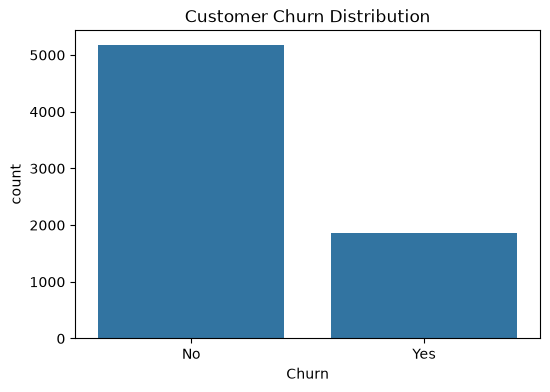

In [15]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="Churn",
    data=data
)

plt.title("Customer Churn Distribution")
plt.show()

# Exploratory Data Analysis (EDA)

## Objective

Exploratory Data Analysis (EDA) helps understand the characteristics of the dataset before preprocessing and model building.

The objectives of EDA are:

- Understand the distribution of features.
- Analyze customer demographics.
- Identify patterns related to customer churn.
- Detect class imbalance.
- Gain business insights from the data.

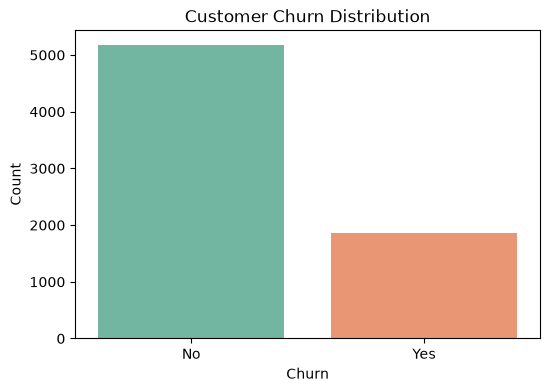

In [16]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="Churn",
    data=data,
    palette="Set2"
)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.show()

## Interpretation

The chart shows the distribution of customers who have churned and those who have not.

This helps determine whether the dataset is balanced or imbalanced before training machine learning models.

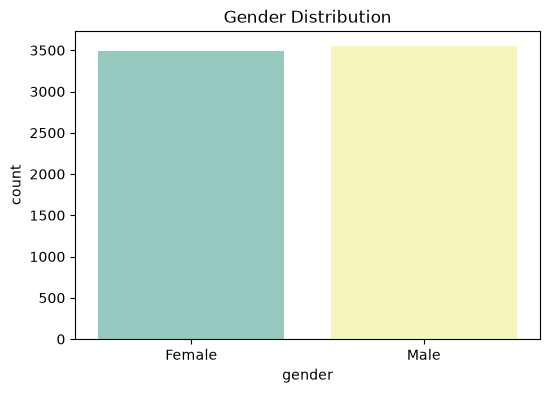

In [17]:
plt.figure(figsize=(6,4))
sns.countplot(
    x="gender",
    data=data,
    palette="Set3"
)
plt.title("Gender Distribution")
plt.show()

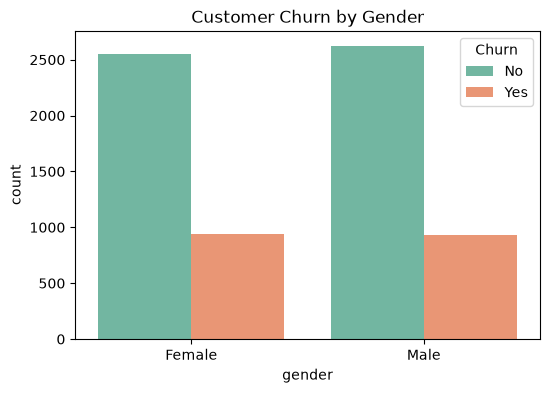

In [18]:
#churn by gender
plt.figure(figsize=(6,4))
sns.countplot(
    x="gender",
    hue="Churn",
    data=data,
    palette="Set2"
)
plt.title("Customer Churn by Gender")
plt.show()

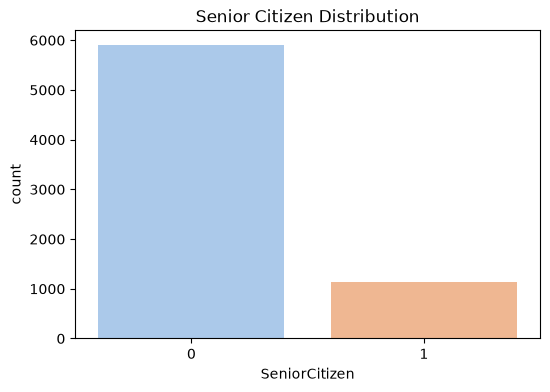

In [19]:
plt.figure(figsize=(6,4))
sns.countplot(
    x="SeniorCitizen",
    data=data,
    palette="pastel"
)
plt.title("Senior Citizen Distribution")
plt.show()

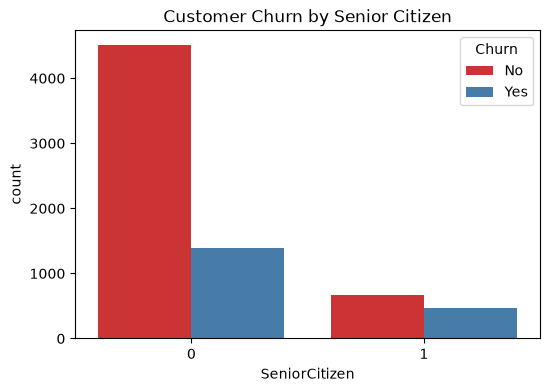

In [20]:
#churn by senior Citizen
plt.figure(figsize=(6,4))
sns.countplot(
    x="SeniorCitizen",
    hue="Churn",
    data=data,
    palette="Set1"
)
plt.title("Customer Churn by Senior Citizen")
plt.show()

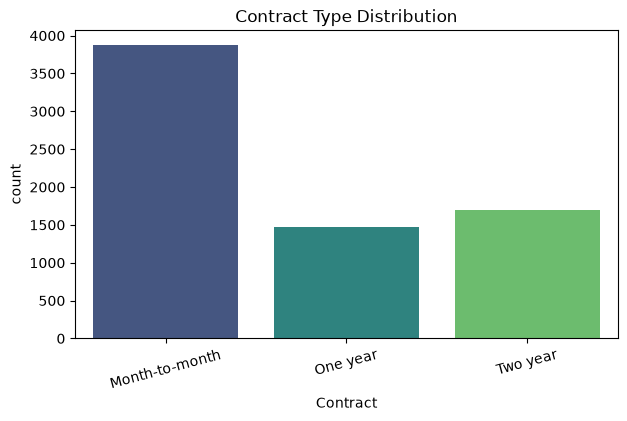

In [21]:
plt.figure(figsize=(7,4))
sns.countplot(
    x="Contract",
    data=data,
    palette="viridis"
)
plt.title("Contract Type Distribution")
plt.xticks(rotation=15)
plt.show()

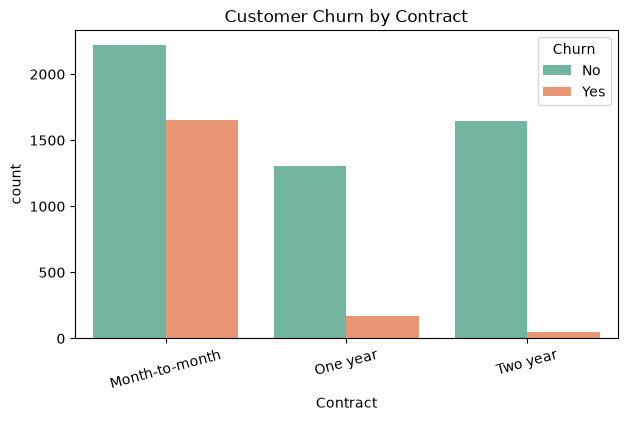

In [22]:
#churn by contract
plt.figure(figsize=(7,4))
sns.countplot(
    x="Contract",
    hue="Churn",
    data=data,
    palette="Set2"
)
plt.title("Customer Churn by Contract")
plt.xticks(rotation=15)
plt.show()

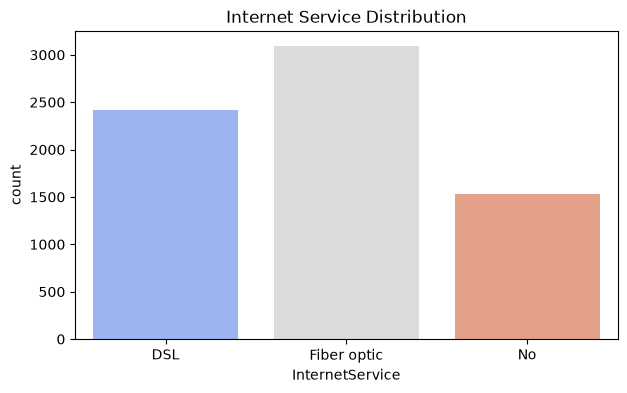

In [23]:
plt.figure(figsize=(7,4))

sns.countplot(
    x="InternetService",
    data=data,
    palette="coolwarm"
)

plt.title("Internet Service Distribution")

plt.show()

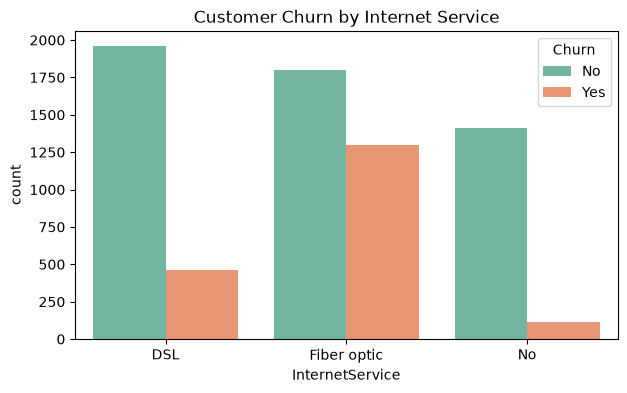

In [24]:
#churn by Internetservice
plt.figure(figsize=(7,4))

sns.countplot(
    x="InternetService",
    hue="Churn",
    data=data,
    palette="Set2"
)

plt.title("Customer Churn by Internet Service")

plt.show()

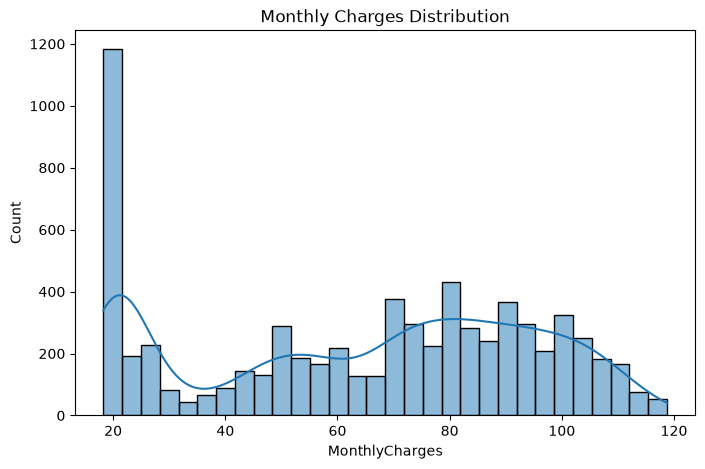

In [25]:
#monthly charge distribution
plt.figure(figsize=(8,5))

sns.histplot(
    data["MonthlyCharges"],
    bins=30,
    kde=True
)

plt.title("Monthly Charges Distribution")

plt.show()

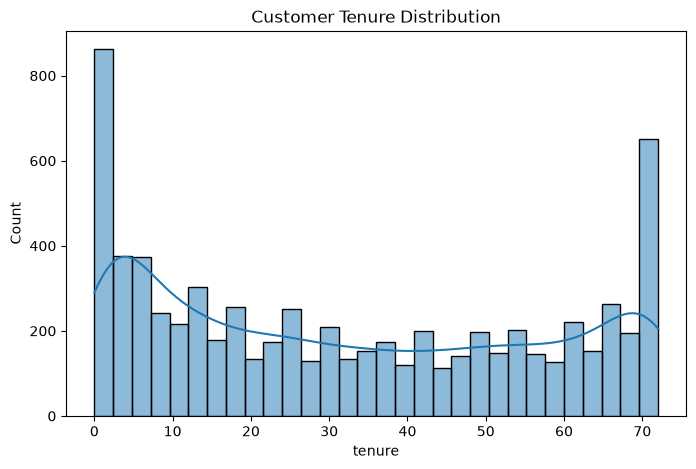

In [26]:
#distribution by tenure
plt.figure(figsize=(8,5))

sns.histplot(
    data["tenure"],
    bins=30,
    kde=True
)

plt.title("Customer Tenure Distribution")

plt.show()

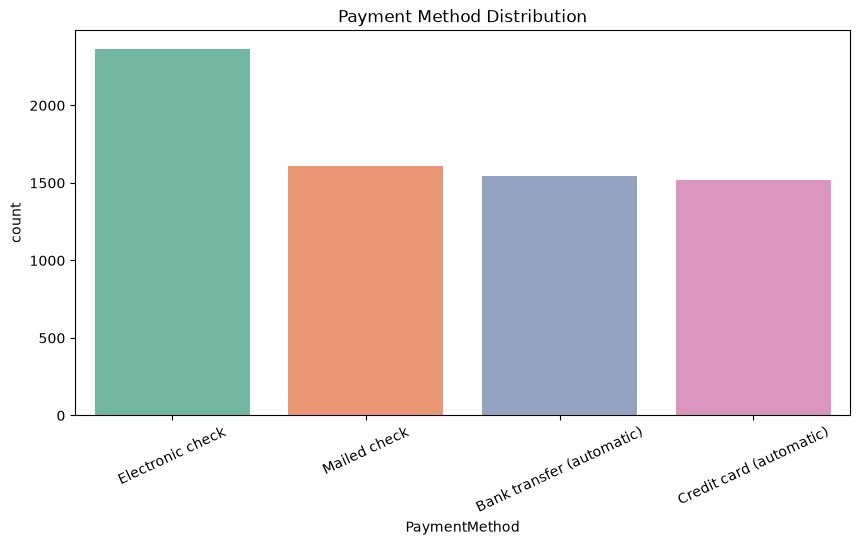

In [27]:
#payment method Distribution
plt.figure(figsize=(10,5))

sns.countplot(
    x="PaymentMethod",
    data=data,
    hue="PaymentMethod",
    palette="Set2",
    legend=False
)

plt.xticks(rotation=25)

plt.title("Payment Method Distribution")

plt.show()

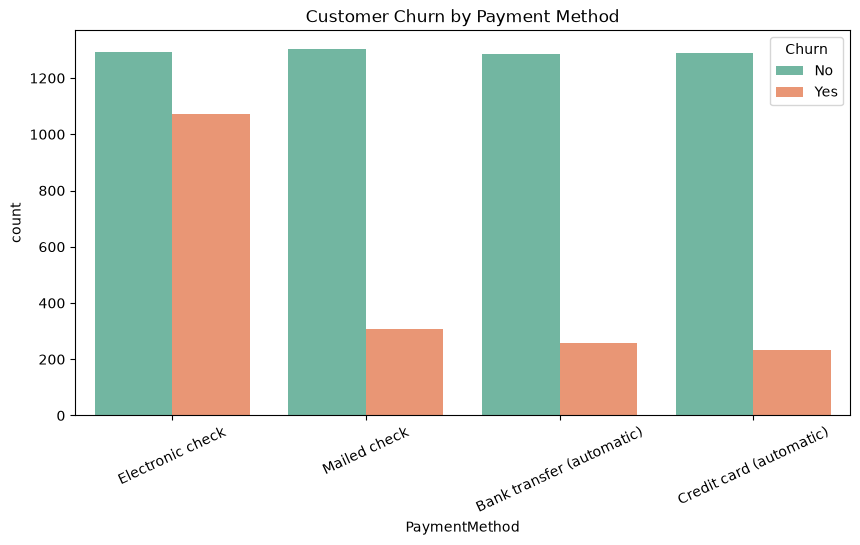

In [28]:
#churn by payment method
plt.figure(figsize=(10,5))

sns.countplot(
    x="PaymentMethod",
    hue="Churn",
    data=data,
    palette="Set2"
)

plt.xticks(rotation=25)

plt.title("Customer Churn by Payment Method")

plt.show()

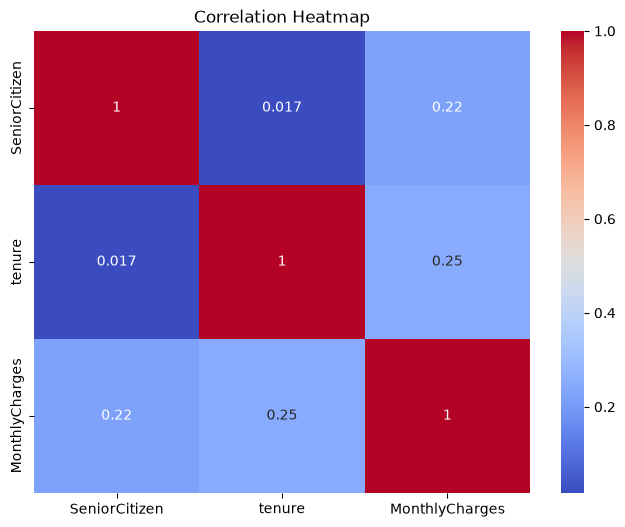

In [29]:
plt.figure(figsize=(8,6))
sns.heatmap(
    data.select_dtypes(include=["int64","float64"]).corr(),
    annot=True,
    cmap="coolwarm"    
)
plt.title("Correlation Heatmap")
plt.show()

# EDA Summary

Key observations from the exploratory data analysis include:

- The dataset is imbalanced, with more customers staying than leaving.
- Month-to-month contract customers show a higher tendency to churn.
- Customers with Fiber Optic internet service appear to churn more frequently.
- Customers with shorter tenure are more likely to leave the company.
- Customers paying through Electronic Check exhibit relatively higher churn.
- Monthly charges are generally higher among customers who churn.

These observations provide useful business insights and guide the preprocessing and model-building stages.

# Removing CustomerID

## Objective

The `customerID` column is a unique identifier assigned to each customer.

Since it does not contain any meaningful information for predicting customer churn, it is removed before training the machine learning models.

In [30]:
data=data.drop(columns="customerID") #or use axis=1
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Checking TotalCharges

The `TotalCharges` column should contain numerical values.

However, it is often stored as an object (string) because some records contain blank spaces.

Therefore, we first inspect its data type before converting it into a numeric format.

In [31]:
data.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

# Converting TotalCharges to Numeric

## Objective

The `TotalCharges` column is stored as a string instead of a numeric data type.

This occurs because some rows contain blank values.

Since machine learning algorithms require numerical inputs, the column must be converted to a numeric format.

The `errors="coerce"` parameter converts invalid values (such as blank spaces) into `NaN`, allowing them to be handled during preprocessing.

In [32]:
#converting total charge to numeric type
data["TotalCharges"]=pd.to_numeric(
    data["TotalCharges"],
    errors="coerce" #converts valid values into numeric format and replaces invalid or blank values with NaN
)
data["TotalCharges"].dtypes

dtype('float64')

In [33]:
data.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [34]:
#Total Charges = 11

# Handling Missing Values

After converting `TotalCharges` to a numeric data type, a few missing values appear because some records originally contained blank entries.

Since only a very small number of records are affected, these rows are removed to maintain data quality without significantly impacting the dataset.

In [35]:
#removing the missing value 
data.dropna(inplace=True)

In [36]:
data.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

# Identifying Feature Types

## Objective

Machine learning algorithms require numerical inputs.

Before encoding, we identify:

- **Categorical Features** → Need encoding.
- **Numerical Features** → Used directly (and later scaled).

This step helps us choose the correct preprocessing technique for each feature type.

In [37]:
categorical_cols=data.select_dtypes(include=["object"]).columns
print("Categorical_cols")
print(categorical_cols)

Categorical_cols
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')


In [38]:
numerical_cols=data.select_dtypes(include=["int64","float64"]).columns
print("Numerical_cols")
print(numerical_cols)

Numerical_cols
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')


# Encoding Categorical Features

## Objective

Machine learning algorithms require numerical input features. Since the dataset contains several categorical variables, they must be converted into a numerical format before model training.

The encoding strategy is based on the number of unique categories present in each feature.

### Binary Categorical Features

Features containing only two categories are encoded using **Binary Encoding (Label Mapping)**.

Examples:

- Female → 0, Male → 1
- No → 0, Yes → 1

Binary encoding is efficient because no ordinal relationship is introduced.

---

### Multi-Class Categorical Features

Features containing more than two categories are encoded using **One-Hot Encoding**.

One-Hot Encoding creates a separate binary column for each category, preventing the model from assuming any ordinal relationship among categories.

For example:

| Contract | Month-to-month | One year | Two year |
|----------|---------------|----------|----------|
| Month-to-month | 1 | 0 | 0 |
| One year | 0 | 1 | 0 |
| Two year | 0 | 0 | 1 |

This approach is widely used for categorical variables in machine learning classification problems.


In [39]:
#Binary Encoding
binary_mapping={
    "gender":{
        "Female":0,
        "Male":1
    },
    "Partner":{
        "No":0,
        "Yes":1
    },
    "Dependents":{
        "No":0,
        "Yes":1
    },
    "PhoneService":{
        "No":0,
        "Yes":1
    },
    "PaperlessBilling":{
        "No":0,
        "Yes":1
    },
    "Churn":{
        "No":0,
        "Yes":1
    }
}
for column, mapping in binary_mapping.items():
    data[column]=data[column].map(mapping)

In [40]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


# One-Hot Encoding

The remaining categorical variables contain more than two unique categories.

These variables are converted into numerical features using One-Hot Encoding.

The parameter `drop_first=True` is used to remove one redundant category from each feature.

This helps:

- Reduce multicollinearity
- Avoid the Dummy Variable Trap
- Improve model efficiency

In [41]:
#one hot encoding for multi categorical columns
multi_class_columns=[
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaymentMethod"
]
data=pd.get_dummies(
    data,
    columns=multi_class_columns,
    drop_first=True,
    dtype=int
)
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,0,0,0,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,0,0,0,0,0,0,0,0,1,0


# Splitting Features and Target Variable

## Objective

Machine learning models require the input features (X) and the target variable (y) to be separated.

- **X** contains all independent variables used for prediction.
- **y** contains the target variable (Customer Churn).

In [42]:
X=data.drop("Churn",axis=1)
y=data["Churn"]
print("Feature Shape:",X.shape)
print("Target Shape:",y.shape)

Feature Shape: (7032, 30)
Target Shape: (7032,)


# Train-Test Split

## Objective

The dataset is divided into training and testing sets.

- **Training Set** → Used to train the model.
- **Testing Set** → Used to evaluate model performance on unseen data.

The dataset is split into:

- 80% Training Data
- 20% Testing Data

In [43]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,
    test_size=0.20,
    random_state=42,
    stratify=y #stratify=y ensures that the proportion of churned and non-churned customers remains the same in both training and testing datasets.
)
print("Training Shape:",X_train.shape)
print("Testing Shape:",X_test.shape)

Training Shape: (5625, 30)
Testing Shape: (1407, 30)


# Feature Scaling

## Objective

Several machine learning algorithms calculate distances between observations.

Features such as:

- Tenure
- Monthly Charges
- Total Charges

have different numerical ranges.

Standardization transforms the numerical features so that:

- Mean = 0
- Standard Deviation = 1

This prevents features with larger values from dominating the learning process.

Scaling is particularly important for:

- Logistic Regression
- K-Nearest Neighbors
- Support Vector Machine

In [44]:
#standardizing 
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train) # Fit on training data and transform it
X_test_scaled=scaler.transform(X_test) # Transform test data using the same scaler

- fit() learns the mean and standard deviation from the training data.
- transform() scales the training data using those values.
- We only use transform() because the test data should be scaled using the same mean and standard deviation learned from the training data.
- If we used fit_transform() on the test set, it would calculate a new mean and standard deviation, causing data leakage and giving unreliable evaluation results.

In [45]:
from sklearn.linear_model import LogisticRegression #importing algo
log_model=LogisticRegression(random_state=42) #creating model
log_model.fit(X_train_scaled,y_train)  #train model
y_pred=log_model.predict(X_test_scaled) #prediction
y_prob=log_model.predict_proba(X_test_scaled)[:,1] #probablity prediction

# Model Evaluation

## Objective

After training the Logistic Regression model, its performance is evaluated using several classification metrics.

The evaluation metrics help determine how well the model distinguishes between customers who churn and those who do not.

The following metrics are used:

- Accuracy
- Precision
- Recall
- F1 Score
- Confusion Matrix
- Classification Report
- ROC Curve
- ROC-AUC Score

In [46]:
#Model Evaluation
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

## Accuracy
Accuracy represents the proportion of correctly classified observations among all observations.

It is calculated as:

Accuracy = Correct Predictions / Total Predictions
-------
## Precision
Precision measures the proportion of predicted churned customers that actually churned.

High precision means fewer false positives.
-------
## Recall
Recall measures how many actual churned customers were correctly identified.

High recall means fewer false negatives.
-------
## F1 Score
The F1 Score is the harmonic mean of Precision and Recall.

It balances both metrics and is useful when the dataset is imbalanced.
-------
## Classification Report
The classification report provides:

- Precision
- Recall
- F1 Score
- Support
for each class.
-------
## Confusion Matrix
The confusion matrix summarizes model predictions.

It contains:

- True Positives (TP)
- True Negatives (TN)
- False Positives (FP)
- False Negatives (FN)

In [47]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy :", accuracy)

precision = precision_score(y_test, y_pred)
print("Precision :", precision)

recall = recall_score(y_test, y_pred)
print("Recall :", recall)

f1 = f1_score(y_test, y_pred)
print("F1 Score :", f1)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
cm

Accuracy : 0.8038379530916845
Precision : 0.6475903614457831
Recall : 0.5748663101604278
F1 Score : 0.6090651558073654
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



array([[916, 117],
       [159, 215]])

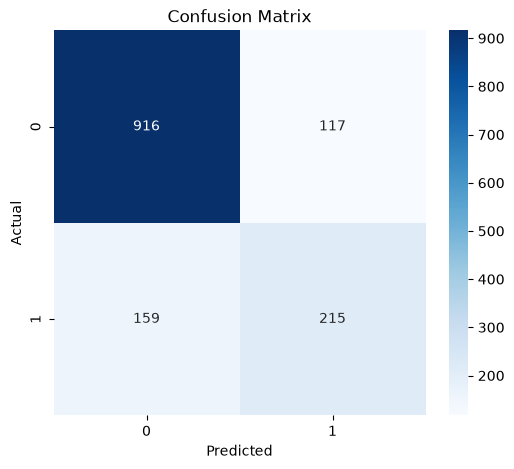

In [48]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## ROC-AUC Score

The ROC-AUC score measures the model's ability to distinguish between churned and non-churned customers.

A value closer to **1** indicates better model performance.

In [49]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

print(y_train.shape)
print(y_test.shape)

print(y_pred.shape)
print(y_prob.shape)

(5625, 30)
(1407, 30)
(5625,)
(1407,)
(1407,)
(1407,)


In [50]:
auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score :", auc)

ROC-AUC Score : 0.8356727976766699


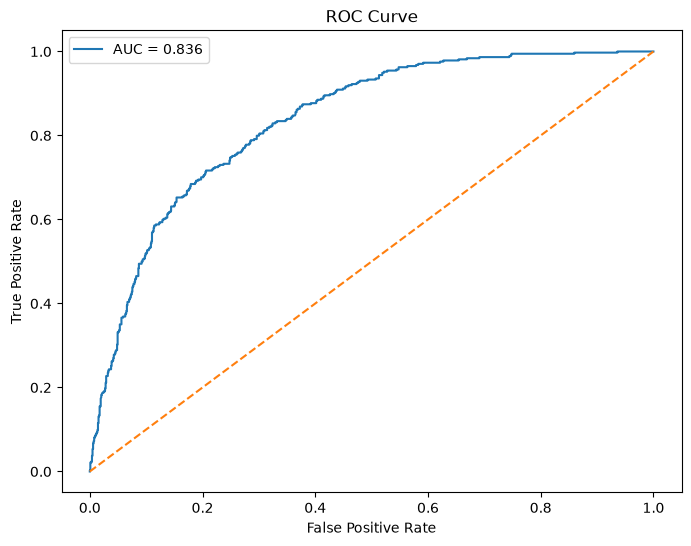

In [51]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.show()

# Logistic Regression Performance

The Logistic Regression model was evaluated using multiple classification metrics.

### Results

| Metric | Score |
|--------|-------|
| Accuracy | **80.38%** |
| Precision | **64.76%** |
| Recall | **57.49%** |
| F1 Score | **60.91%** |
| ROC-AUC Score | **83.57%** |

---

## Interpretation

### Accuracy (80.38%)

The model correctly classified approximately **80%** of customers.

This indicates that Logistic Regression performs well as a baseline classification model.

---

### Precision (64.76%)

Among customers predicted to churn, approximately **65%** actually churned.

This means the model maintains a moderate number of false positive predictions.

---

### Recall (57.49%)

The model correctly identified approximately **57%** of actual churned customers.

This suggests that some churned customers were still classified as non-churn.

Improving recall is important because missing potential churn customers may reduce customer retention opportunities.

---

### F1 Score (60.91%)

The F1 Score represents the balance between Precision and Recall.

A score of **0.61** indicates that the model provides a reasonable trade-off between identifying churned customers and minimizing false predictions.

---

### ROC-AUC Score (83.57%)

The ROC-AUC score indicates that the model has a strong ability to distinguish between churned and non-churned customers.

An AUC value above **0.80** is generally considered a good classification performance.

---

Overall, Logistic Regression provides a solid baseline model for customer churn prediction. More advanced algorithms such as Random Forest, XGBoost, or Gradient Boosting may further improve Recall and F1 Score.

# Confusion Matrix Interpretation

| Actual / Predicted | No Churn | Churn |
|--------------------|---------:|------:|
| **No Churn** | 916 | 117 |
| **Churn** | 159 | 215 |

### Interpretation

- **True Negatives (916):** Customers correctly predicted as not churning.
- **True Positives (215):** Customers correctly predicted as churning.
- **False Positives (117):** Customers predicted to churn but actually did not.
- **False Negatives (159):** Customers who churned but were predicted as non-churn.

The relatively higher number of False Negatives indicates that the model misses some customers who are likely to churn. Reducing False Negatives should be a priority because identifying potential churn customers is critical for customer retention strategies.    

# K-Nearest Neighbors (KNN)

## Objective

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm used for classification and regression.

For classification, KNN predicts the class of a new observation based on the majority class among its nearest neighbors.

### Why KNN?

- Simple and intuitive
- Non-parametric algorithm
- No training phase (Lazy Learning)
- Works well on scaled numerical data
- Effective for classification problems

In [52]:
# We'll use the same:
# X_train_scaled
# X_test_scaled
# y_train
# y_test

In [53]:
from sklearn.neighbors import KNeighborsClassifier # using K-value=5 for now
#Create model
knn=KNeighborsClassifier(
    n_neighbors=5
)
#train model
knn.fit(
    X_train_scaled,
    y_train
)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [54]:
#prediction
y_pred_knn=knn.predict(X_test_scaled)
y_prob_knn=knn.predict_proba(X_test_scaled)[:,1]

In [55]:
#Evaluation
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print("Accuracy :", accuracy_knn)

precision_knn = precision_score(y_test, y_pred_knn)
print("Precision :", precision_knn)

recall_knn = recall_score(y_test, y_pred_knn)
print("Recall :", recall_knn)

f1_knn = f1_score(y_test, y_pred_knn)
print("F1 Score :", f1_knn)

auc_knn = roc_auc_score(y_test, y_prob_knn)
print("ROC-AUC :", auc_knn)

Accuracy : 0.7540867093105899
Precision : 0.5374331550802139
Recall : 0.5374331550802139
F1 Score : 0.5374331550802139
ROC-AUC : 0.7671544900632082


In [56]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.83      0.83      0.83      1033
           1       0.54      0.54      0.54       374

    accuracy                           0.75      1407
   macro avg       0.68      0.68      0.68      1407
weighted avg       0.75      0.75      0.75      1407



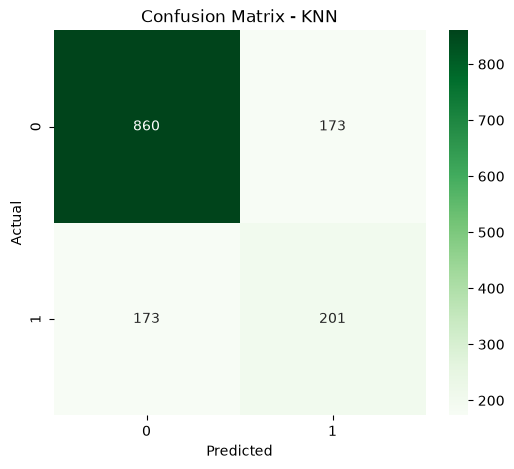

In [57]:
#Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Confusion Matrix - KNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

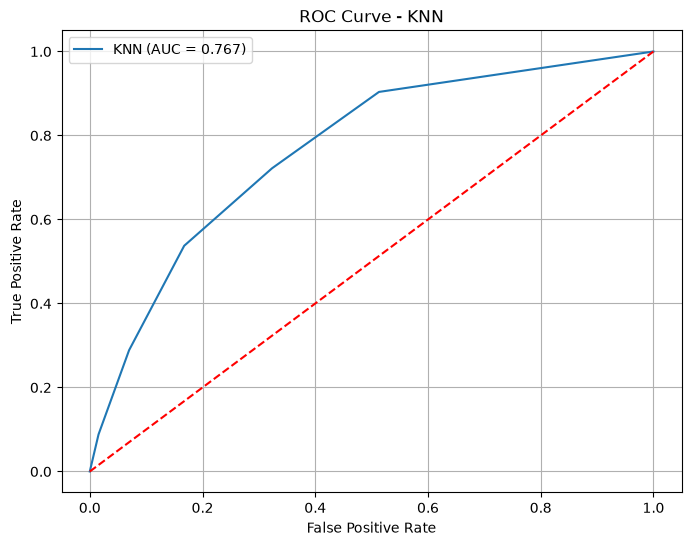

In [58]:
#ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_knn)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f"KNN (AUC = {auc_knn:.3f})"
)

plt.plot([0,1],[0,1],"r--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN")

plt.legend()

plt.grid(True)

plt.show()

# Hyperparameter Tuning for KNN

## Objective

The performance of K-Nearest Neighbors depends on the value of **K (number of neighbors)**.

- Small K → More sensitive to noise (Overfitting)
- Large K → Smoother decision boundary (Underfitting)

To identify the optimal value of K, the model is trained using multiple values of K, and the error rate is compared.

The K with the lowest error rate is selected as the optimal value.

In [59]:
#Finding Error Rate
error_rate=[]
for k in range (1,31):
    knn=KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled,y_train)
    pred_k=knn.predict(X_test_scaled)
    error_rate.append(np.mean(pred_k != y_test))

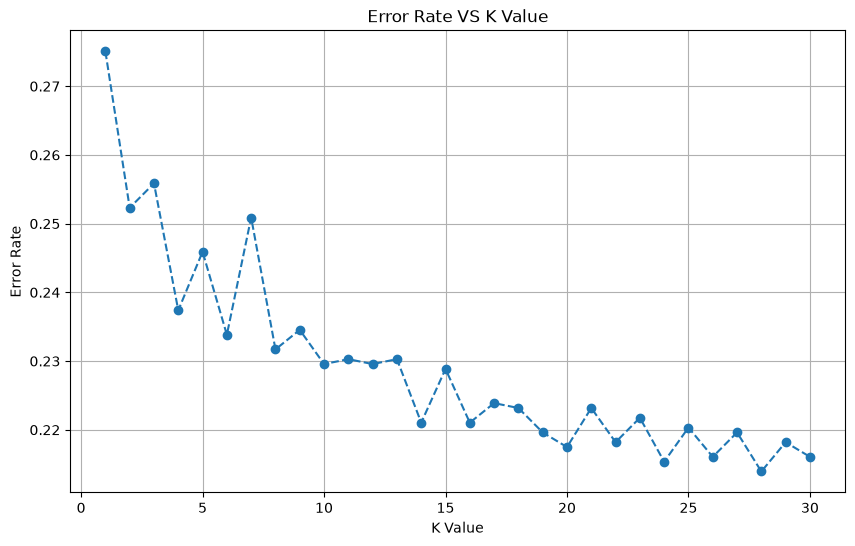

In [60]:
#plot Error Rate
plt.figure(figsize=(10,6))
plt.plot(
    range(1,31),
    error_rate,
    marker="o",
    linestyle="--"
)
plt.title("Error Rate VS K Value")
plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.grid(True)

plt.show()

# KNN Hyperparameter Tuning (Choosing the Best K)

## Interpretation

The graph illustrates the relationship between the **Error Rate** and different values of **K (Number of Neighbors)**.

### Observations

- When **K = 1**, the error rate is the highest (approximately **27.5%**), indicating that the model is highly sensitive to noise and tends to overfit the training data.
- As the value of **K** increases, the error rate decreases steadily, showing that the model becomes more stable and generalizes better.
- After **K ≈ 20**, the error rate stabilizes around **21–22%**, with only small fluctuations.
- The **lowest error rate** is observed around **K = 28**, where the error is approximately **21.4%**.
- Beyond this point, there is no significant improvement in performance.

### Conclusion

Based on the Error Rate vs K graph, **K = 28** is selected as the optimal number of neighbors because it produces the **lowest classification error** while maintaining stable model performance.

Using the optimal value of **K** helps improve the predictive performance of the K-Nearest Neighbors model by reducing overfitting and achieving better generalization on unseen data.

In [61]:
#k=28
knn=KNeighborsClassifier(n_neighbors=28)
knn.fit(X_train_scaled,y_train)
y_pred_knn=knn.predict(X_test_scaled)
y_prob_knn=knn.predict_proba(X_test_scaled)[:,1]

In [62]:
#Evaluation
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print("Accuracy :", accuracy_knn)

precision_knn = precision_score(y_test, y_pred_knn)
print("Precision :", precision_knn)

recall_knn = recall_score(y_test, y_pred_knn)
print("Recall :", recall_knn)

f1_knn = f1_score(y_test, y_pred_knn)
print("F1 Score :", f1_knn)

auc_knn = roc_auc_score(y_test, y_prob_knn)
print("ROC-AUC :", auc_knn)

Accuracy : 0.7860696517412935
Precision : 0.6070381231671554
Recall : 0.553475935828877
F1 Score : 0.579020979020979
ROC-AUC : 0.8180614585004996


# Logistic Regression vs K-Nearest Neighbors

## Performance Comparison

| Metric | Logistic Regression | KNN (K=28) |
|--------|--------------------:|-----------:|
| Accuracy | 80.38% | 78.61% |
| Precision | 64.76% | 60.70% |
| Recall | 57.49% | 55.35% |
| F1 Score | 60.91% | 57.90% |
| ROC-AUC | 83.57% | 81.81% |

---

## Interpretation

After evaluating both models, **Logistic Regression outperformed K-Nearest Neighbors** across all evaluation metrics.

### Logistic Regression

- Achieved the highest Accuracy (80.38%).
- Produced better Precision and Recall.
- Obtained the highest F1 Score.
- Recorded the best ROC-AUC score (83.57%), indicating stronger discrimination between churned and non-churned customers.

### K-Nearest Neighbors

- Performance improved after selecting the optimal K value using hyperparameter tuning.
- Despite optimization, KNN produced slightly lower Accuracy, Precision, Recall, F1 Score, and ROC-AUC than Logistic Regression.

---

## Conclusion

For this dataset, **Logistic Regression provides better overall classification performance than K-Nearest Neighbors**.

Although KNN is simple and intuitive, Logistic Regression demonstrates stronger predictive capability and serves as a better baseline model for customer churn prediction.

# Decision Tree Classification

## Objective

Decision Tree is a supervised machine learning algorithm used for classification and regression tasks.

It predicts the target variable by recursively splitting the dataset into smaller subsets based on the most informative features.

In this project, the Decision Tree model is used to predict whether a customer is likely to churn based on customer demographics and service-related features.

---

## Why Decision Tree?

- Easy to understand and interpret.
- Can handle both numerical and categorical features.
- Captures non-linear relationships.
- Performs automatic feature selection during training.
- Provides feature importance for better business understanding.

In [63]:
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(           #create model
    criterion="gini",
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=4   
)
dt_model.fit(                              #train model
    X_train_scaled,
    y_train
)
#Improving the model again

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",4
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

In [64]:
y_pred_dt = dt_model.predict(X_test_scaled)
y_prob_dt = dt_model.predict_proba(X_test_scaled)[:,1]

In [65]:
#Evaluation
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Accuracy :", accuracy_dt)

precision_dt = precision_score(y_test, y_pred_dt)
print("Precision :", precision_dt)

recall_dt = recall_score(y_test, y_pred_dt)
print("Recall :", recall_dt)

f1_dt = f1_score(y_test, y_pred_dt)
print("F1 Score :", f1_dt)

auc_dt = roc_auc_score(y_test, y_prob_dt)
print("ROC-AUC :", auc_dt)

Accuracy : 0.7782515991471215
Precision : 0.5807291666666666
Recall : 0.5962566844919787
F1 Score : 0.5883905013192612
ROC-AUC : 0.8197089625254307


In [66]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.85      0.84      0.85      1033
           1       0.58      0.60      0.59       374

    accuracy                           0.78      1407
   macro avg       0.72      0.72      0.72      1407
weighted avg       0.78      0.78      0.78      1407



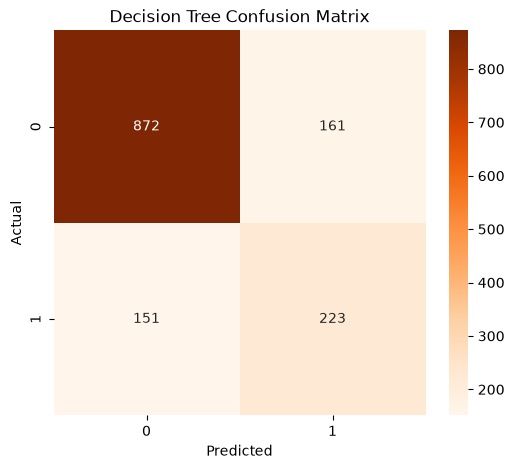

In [67]:
#confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

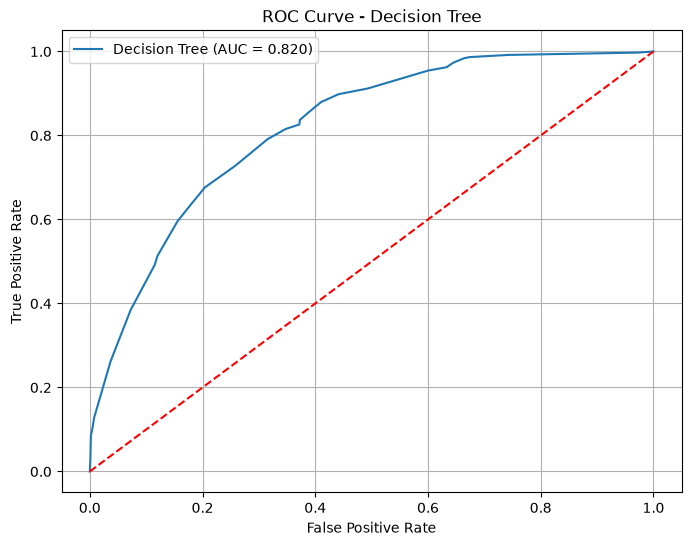

In [68]:
#ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_dt)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f"Decision Tree (AUC = {auc_dt:.3f})"
)

plt.plot([0,1],[0,1],"r--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")

plt.legend()

plt.grid(True)

plt.show()

# Decision Tree Visualization

## Objective

A Decision Tree can be visualized to understand how the model makes predictions.

Each node represents a decision based on a feature.

The tree continues splitting until it reaches a leaf node, where the final prediction is made.

Visualizing the tree helps understand:

- Feature importance
- Decision rules
- Model complexity
- Overfitting

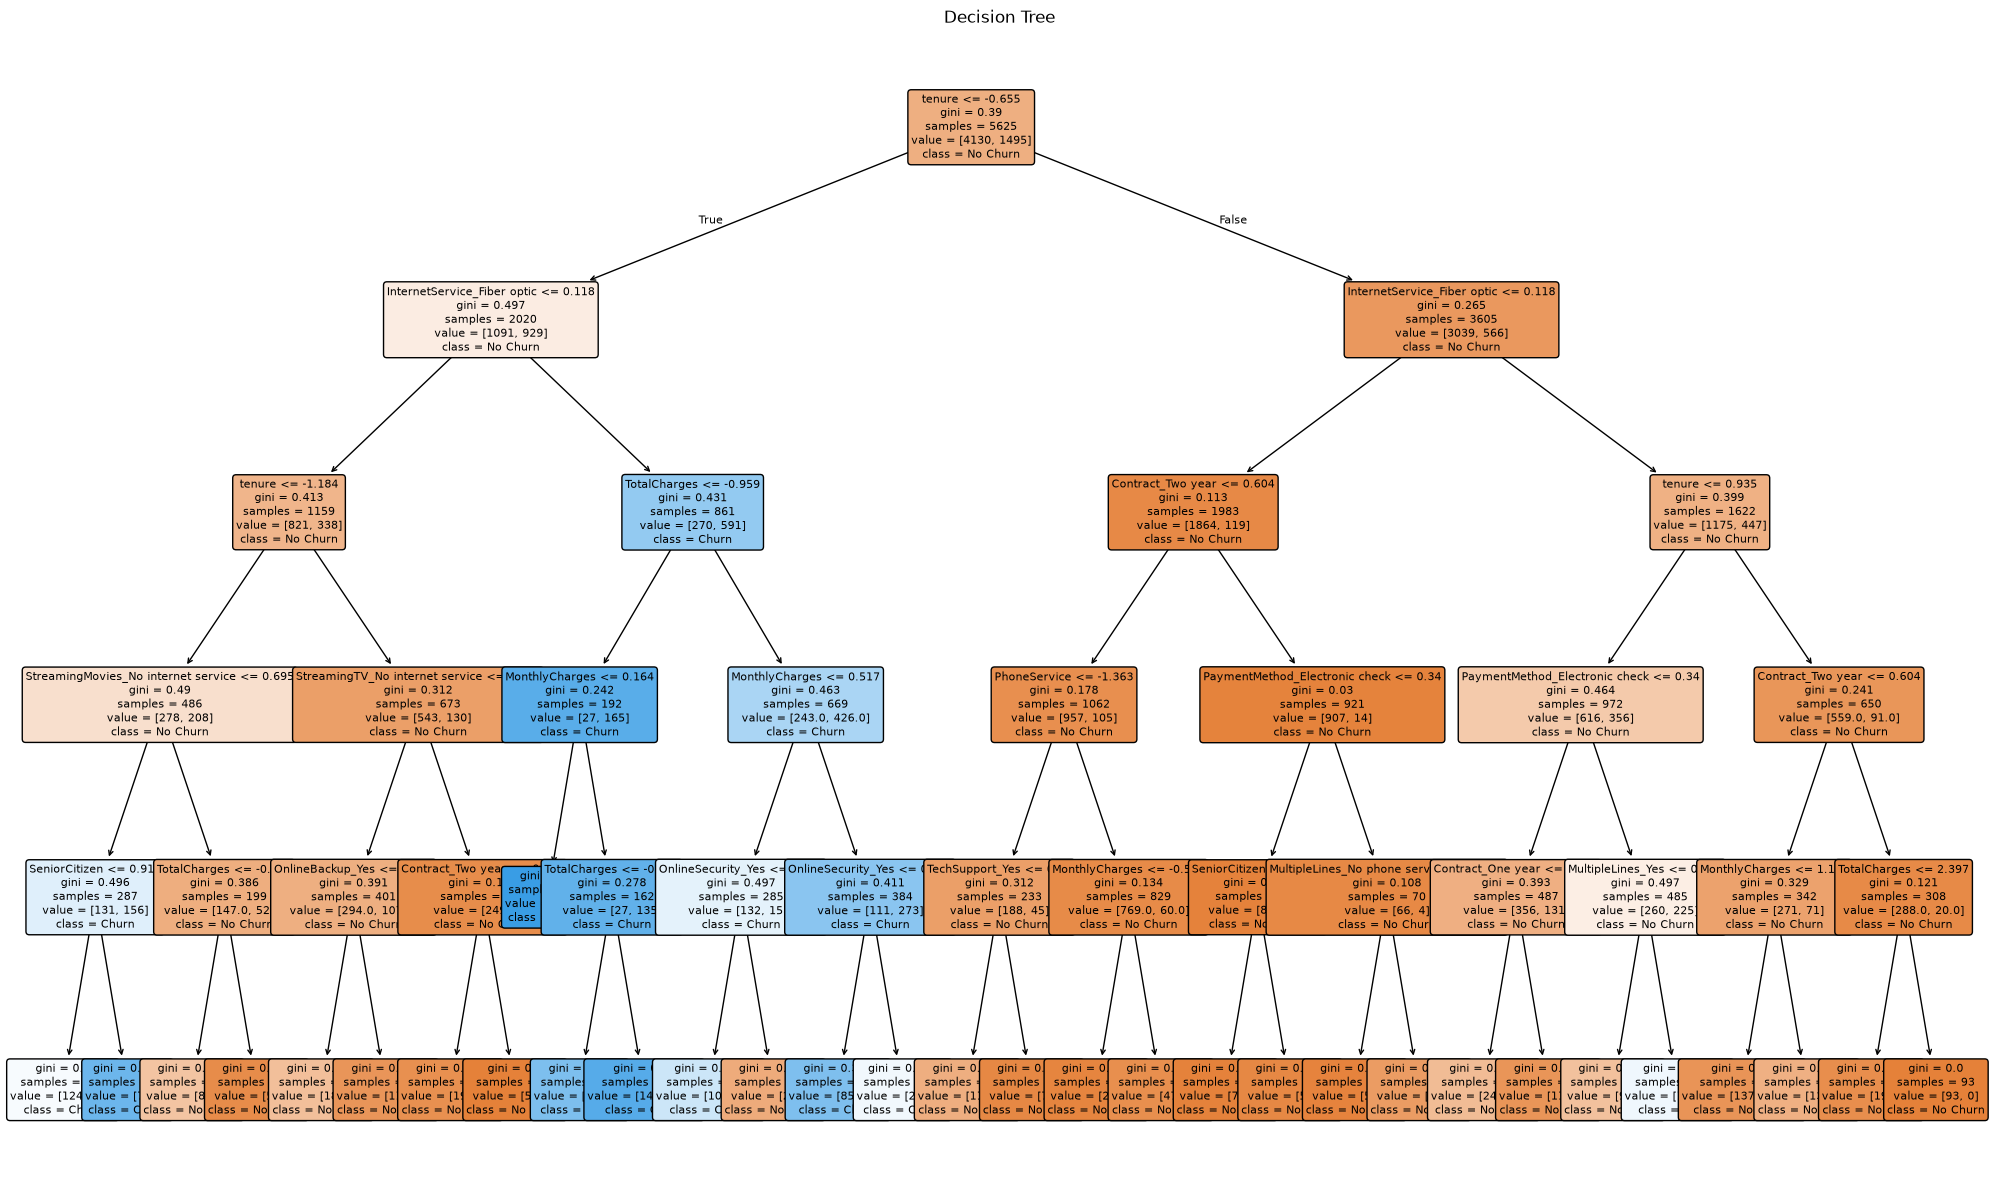

In [69]:
from sklearn.tree import plot_tree
plt.figure(figsize=(25,15))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree")

plt.show()

In [70]:
# training the model again with this value :

#    criterion="gini",
#    max_depth=5,
#    min_samples_split=20,
#    min_samples_leaf=10,
#   random_state=42


# Feature Importance

## Objective

Decision Trees rank features according to their importance during splitting.

More important features contribute more toward reducing impurity and improving prediction accuracy.

Feature importance helps identify the most influential variables affecting customer churn.

In [71]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
4,tenure,0.444868
11,InternetService_Fiber optic,0.341579
8,TotalCharges,0.033407
28,PaymentMethod_Electronic check,0.027008
23,StreamingMovies_No internet service,0.026996
7,MonthlyCharges,0.023606
26,Contract_Two year,0.020763
21,StreamingTV_No internet service,0.015527
14,OnlineSecurity_Yes,0.015261
10,MultipleLines_Yes,0.010216


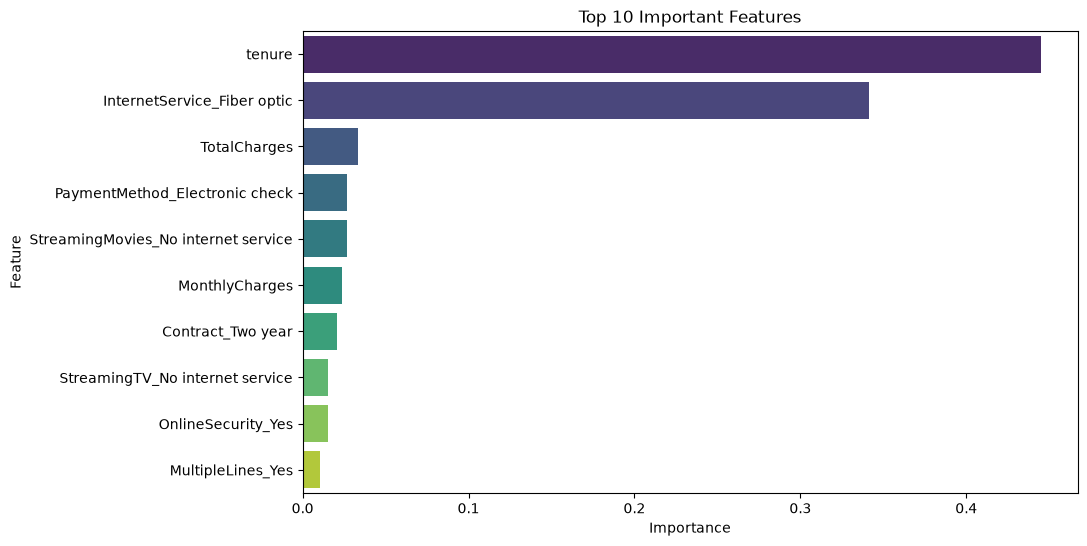

In [72]:
#visualization
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature",
    hue="Feature",      # Added for seaborn compatibility
    legend=False,
    palette="viridis"
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## Feature Importance Interpretation

The Decision Tree identifies the most influential features used to predict customer churn.

The two most important features are:

1. **Tenure**
2. **Internet Service (Fiber Optic)**

Together, these features contribute nearly 80% of the model's decision-making process.

### Key Business Insights

- Customers with shorter tenure are significantly more likely to churn.
- Fiber Optic customers show higher churn risk than customers using other internet services.
- Customers with higher monthly charges also have a greater tendency to churn.
- Customers with Two-Year contracts are more likely to remain with the company.
- Online Security and Streaming Services have a smaller but meaningful influence on customer retention.

Understanding feature importance helps businesses identify the primary drivers of customer churn and prioritize customer retention strategies.

# Hyperparameter Tuning using GridSearchCV

## Objective

The default Decision Tree may overfit the training data by creating a very deep tree.

Hyperparameter tuning helps find the optimal combination of parameters that improves model performance while reducing overfitting.

The following hyperparameters are tuned:

- Criterion
- Maximum Depth
- Minimum Samples Split
- Minimum Samples Leaf

GridSearchCV performs an exhaustive search over all parameter combinations using cross-validation and selects the best-performing model.

In [73]:
from sklearn.model_selection import GridSearchCV #importing grid search cv 
#defining parameters
param_grid={
    "criterion":["gini","entropy"],
    "max_depth":[3,5,7,10],
    "min_samples_split":[2,5,10,20],
    "min_samples_leaf":[1,2,5,10]    
}

In [74]:
#Creating base model
dt=DecisionTreeClassifier(random_state=42)
#grid Search 
grid_search=GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1    
)
grid_search.fit(X_train_scaled,y_train)

Fitting 5 folds for each of 128 candidates, totalling 640 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_ex

In [75]:
#best parameter
print("Best Parameters:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)

Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best F1 Score: 0.5852268719799805


In [76]:
# now using the best model grid search and evaluate it on test set
best_dt=grid_search.best_estimator_
y_pred=best_dt.predict(X_test_scaled)
y_prob=best_dt.predict_proba(X_test_scaled)[:,1]

# Evaluating the Optimized Decision Tree

The optimized Decision Tree model was evaluated on the test dataset using multiple classification metrics.

The evaluation includes:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC Score
- Classification Report
- Confusion Matrix

These metrics help measure not only the overall correctness of the model but also its ability to correctly identify churned customers.

In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", accuracy)
print("Precision :", precision)
print("Recall :", recall)
print("F1 Score :", f1)
print("ROC-AUC :", roc_auc)

print("\nClassification Report\n")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix\n")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.751954513148543
Precision : 0.5288683602771362
Recall : 0.6122994652406417
F1 Score : 0.5675340768277571
ROC-AUC : 0.78232369247972

Classification Report

              precision    recall  f1-score   support

           0       0.85      0.80      0.83      1033
           1       0.53      0.61      0.57       374

    accuracy                           0.75      1407
   macro avg       0.69      0.71      0.70      1407
weighted avg       0.77      0.75      0.76      1407


Confusion Matrix

[[829 204]
 [145 229]]


## Decision Tree (After Hyperparameter Tuning)

The optimized Decision Tree model was evaluated using the best parameters obtained from GridSearchCV.

### Results

- **Accuracy:** 75.20%
- **Precision:** 52.89%
- **Recall:** 61.23%
- **F1 Score:** 56.75%
- **ROC-AUC Score:** 78.23%

### Interpretation

The tuned model achieved a higher recall compared to the original Decision Tree, indicating that it identified more churn customers.

However, this improvement came at the cost of lower precision and accuracy, resulting in more false positive predictions.

Overall, the tuned Decision Tree did not outperform the original model in terms of F1 Score or ROC-AUC. Therefore, the original Decision Tree remains the better-performing model for this dataset.

# Decision Tree Performance Comparison

| Metric    | Before Hyperparameter Tuning | After Hyperparameter Tuning |
|---------  |-----------------------------:|----------------------------:|
| Accuracy  |         **78.61%**           |      **75.20%**             |
| Precision |         **60.70%**           |      **52.89%**             |
| Recall    |         **55.35%**           |      **61.23%**             |
| F1 Score  |         **57.90%**           |      **56.75%**             |
| ROC-AUC   |         **81.81%**           |      **78.23%**             |

## Conclusion

- The tuned Decision Tree achieved a **higher Recall**, meaning it detected more customers who were likely to churn.
- However, this improvement came at the cost of **lower Precision**, **Accuracy**, **F1 Score**, and **ROC-AUC**.
- The increase in False Positives reduced the overall effectiveness of the model.
- Therefore, the **original Decision Tree** provides a better balance between correctly identifying churned customers and minimizing incorrect churn predictions.

**Selected Model:** ✅ Original Decision Tree

In [78]:
#Random Model

In [79]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to improve prediction accuracy and reduce overfitting.

Instead of relying on a single tree, Random Forest creates many Decision Trees using random subsets of the training data and features. The final prediction is obtained through majority voting, making the model more robust and stable than a single Decision Tree.

In [80]:
rf=RandomForestClassifier(
    random_state=42
)
rf.fit(X_train_scaled,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

# Training the Random Forest Model

A Random Forest classifier is trained using the standardized training dataset.

Initially, the model is trained with default parameters to establish a baseline performance before applying hyperparameter tuning.

In [81]:
y_pred = rf.predict(X_test_scaled)

y_prob = rf.predict_proba(X_test_scaled)[:,1]

# Model Prediction

The trained Random Forest model is used to predict customer churn on the test dataset.

Both predicted class labels and prediction probabilities are generated for model evaluation.

In [82]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", accuracy)
print("Precision :", precision)
print("Recall :", recall)
print("F1 Score :", f1)
print("ROC-AUC :", roc_auc)

print(classification_report(y_test,y_pred))

print(confusion_matrix(y_test,y_pred))

Accuracy : 0.7867803837953091
Precision : 0.6217105263157895
Recall : 0.5053475935828877
F1 Score : 0.5575221238938053
ROC-AUC : 0.8141970067970865
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

[[918 115]
 [185 189]]


# Model Evaluation

The Random Forest classifier is evaluated using:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC Score
- Classification Report
- Confusion Matrix

These evaluation metrics provide a comprehensive understanding of the model's performance in identifying customer churn.

In [83]:
#Features Importance(which feature contributes the most)
feature_importance=pd.DataFrame({
    "Feature":X_train.columns,
    "Importance":rf.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
8,TotalCharges,0.198838
4,tenure,0.171546
7,MonthlyCharges,0.168485
28,PaymentMethod_Electronic check,0.039660
11,InternetService_Fiber optic,0.035149
0,gender,0.028965
26,Contract_Two year,0.026683
14,OnlineSecurity_Yes,0.026053
6,PaperlessBilling,0.025548
20,TechSupport_Yes,0.023722


# Interpretation

The Random Forest model identified the most influential features for predicting customer churn based on their importance scores.

### Key Insights

- **TotalCharges (0.1988)** is the most important feature, indicating that the customer's total spending has the strongest influence on churn prediction.
- **Tenure (0.1715)** is the second most important feature. Customers with shorter tenures are generally more likely to churn than long-term customers.
- **MonthlyCharges (0.1685)** also has a significant impact, suggesting that customers with higher monthly bills are more likely to leave.
- **PaymentMethod_Electronic check (0.0397)** is the most influential payment method, indicating that customers using electronic checks have a higher tendency to churn.
- **InternetService_Fiber optic (0.0351)** is another important factor, showing that fiber optic users are relatively more likely to churn than customers using other internet services.
- **Contract_Two year (0.0267)** contributes to churn prediction, indicating that customers with longer contracts are generally more loyal.
- **OnlineSecurity_Yes (0.0261)** and **TechSupport_Yes (0.0237)** suggest that customers who subscribe to additional security and support services are less likely to churn.
- **PaperlessBilling (0.0255)** also influences customer behavior, although its impact is lower than billing and tenure-related features.
- **Gender (0.0290)** has a relatively small importance, indicating that customer gender has little effect on churn prediction.

### Conclusion

The feature importance analysis shows that **billing-related variables (TotalCharges and MonthlyCharges)** and **customer relationship variables (Tenure and Contract)** are the strongest predictors of customer churn. Service-related features such as **Online Security** and **Tech Support** also contribute to customer retention, while demographic features like **Gender** have minimal influence on the model's predictions.

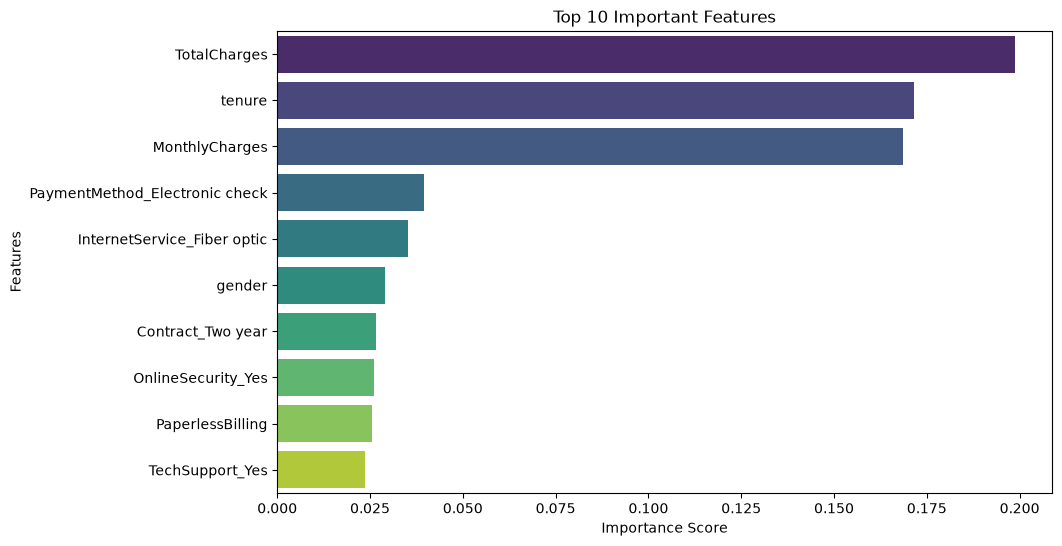

In [92]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

# Interpretation

The bar chart ranks the ten most important features used by the Random Forest model.

Features with larger importance scores contribute more to predicting customer churn, while lower-ranked features have less influence on the final prediction.

This analysis helps identify the key business factors responsible for customer churn.

In [93]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added

In [94]:
grid_search.best_params_

{'max_depth': 10,
 'max_features': 'sqrt',
 'min_samples_leaf': 2,
 'min_samples_split': 10,
 'n_estimators': 100}

In [95]:
best_rf = grid_search.best_estimator_

y_pred_rf = best_rf.predict(X_test)

In [96]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", accuracy)
print("Precision :", precision)
print("Recall :", recall)
print("F1 Score :", f1)
print("ROC-AUC :", roc_auc)

print(classification_report(y_test,y_pred))

print(confusion_matrix(y_test,y_pred))

Accuracy : 0.7867803837953091
Precision : 0.6217105263157895
Recall : 0.5053475935828877
F1 Score : 0.5575221238938053
ROC-AUC : 0.8141970067970865
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

[[918 115]
 [185 189]]


## Random Forest Model Evaluation

The Random Forest model was evaluated using multiple classification metrics including Accuracy, Precision, Recall, F1 Score, ROC-AUC Score, Classification Report, and Confusion Matrix.

### Performance Metrics

| Metric | Score |
|--------|-------|
| Accuracy | 78.68% |
| Precision | 62.17% |
| Recall | 50.53% |
| F1 Score | 55.75% |
| ROC-AUC | 81.42% |

---

## Confusion Matrix

The confusion matrix obtained from the Random Forest model is:

- **True Negative (918):**  
  The model correctly predicted customers who will not churn.

- **False Positive (115):**  
  Customers predicted as churners but actually stayed.

- **False Negative (185):**  
  Customers predicted as non-churners but actually left the service.

- **True Positive (189):**  
  The model correctly identified customers who churned.

---

## Classification Report Analysis

| Class | Precision | Recall | F1-Score | Support |
|-------|-----------|--------|----------|---------|
| 0 (Non-Churn) | 83% | 89% | 86% | 1033 |
| 1 (Churn) | 62% | 51% | 56% | 374 |

### Class 0: Non-Churn Customers

- The model performs well in identifying customers who are likely to stay.
- It achieved:
  - **83% Precision**
  - **89% Recall**
  - **86% F1-score**

This indicates that the model can accurately classify most loyal customers.

### Class 1: Churn Customers

- The model achieved:
  - **62% Precision**
  - **51% Recall**
  - **56% F1-score**

The model identifies some customers who are likely to churn, but it misses several actual churn cases.

The **185 False Negatives** indicate customers who were predicted as staying but actually left. Since the main objective of churn prediction is to identify customers at risk, improving recall for churn customers is important.

---

## Business Insights

- The Random Forest model achieved **78.68% accuracy**, showing good overall predictive performance.
- The **ROC-AUC score of 81.42%** indicates that the model has a good ability to distinguish between churn and non-churn customers.
- The model performs better in identifying customers who stay compared to customers who leave.
- Lower recall for churn customers indicates that some high-risk customers may not be detected early.

### Possible Improvements

To improve churn detection performance:

- Apply **SMOTE (Synthetic Minority Oversampling Technique)** to handle class imbalance.
- Perform additional **Hyperparameter Tuning**.
- Adjust the classification threshold to increase churn recall.
- Compare Random Forest performance with other classification models:
  - Logistic Regression
  - K-Nearest Neighbors (KNN)
  - Decision Tree

---

## Conclusion

The Random Forest model provides a strong baseline for customer churn prediction with a good ROC-AUC score of **81.42%**.

The model successfully identifies customer retention patterns; however, improving the detection of churn customers should be the next priority. Techniques such as class balancing, threshold optimization, and model comparison can help build a more effective churn prediction system.

In [97]:
#hyperparameter tuning
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

#RF model
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [98]:
#Giving parameter
param_grid = {
    'n_estimators': [100, 200, 300], #Number of trees in the forest
    'max_depth': [5, 10, 15, None],  #Controls tree depth (preventing overfiting & underfitting)
    'min_samples_split': [2, 5, 10], #Minimum samples required to split a node
    'min_samples_leaf': [1, 2, 4],   #Minimum samples required at a leaf node
    'max_features': ['sqrt', 'log2'] #Number of features considered at each split
}

In [99]:
#Creating gridsearch
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5, #5-fold cross-validation
    scoring='accuracy', #selects best model based on accuracy
    n_jobs=-1 #uses all CPU cores
)

In [100]:
#Train GridSearchCV (test all combinations)
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added

In [101]:
#best parameters
grid_search.best_params_

{'max_depth': 10,
 'max_features': 'sqrt',
 'min_samples_leaf': 2,
 'min_samples_split': 10,
 'n_estimators': 100}

## Interpretation of Best Parameters:-

1. n_estimators = 100
The model performs best with 100 decision trees.
Increasing the number of trees beyond this did not improve performance significantly.
2. max_depth = 10
Each tree is limited to a maximum depth of 10 levels.
This helps prevent overfitting by avoiding overly complex trees.
3. min_samples_split = 10
A node requires at least 10 samples before it can be split.
This creates simpler trees and improves generalization.
4. min_samples_leaf = 2
Each leaf node must contain at least 2 samples.
This reduces the chances of creating very specific rules from small data points.
5. max_features = 'sqrt'
At each split, the model considers the square root of total features.
This increases diversity among trees and improves Random Forest performance.

In [102]:
#tuned random model (best rf model)
best_rf = grid_search.best_estimator_

In [103]:
#prediction
y_pred_tuned = best_rf.predict(X_test)
y_prob_tuned = best_rf.predict_proba(X_test)[:,1]

In [104]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

accuracy = accuracy_score(y_test, y_pred_tuned)
precision = precision_score(y_test, y_pred_tuned)
recall = recall_score(y_test, y_pred_tuned)
f1 = f1_score(y_test, y_pred_tuned)
roc_auc = roc_auc_score(y_test, y_prob_tuned)

print("Accuracy :", accuracy)
print("Precision :", precision)
print("Recall :", recall)
print("F1 Score :", f1)
print("ROC-AUC :", roc_auc)

Accuracy : 0.7945984363894811
Precision : 0.6491228070175439
Recall : 0.4946524064171123
F1 Score : 0.5614567526555387
ROC-AUC : 0.835997639397218


In [105]:
print(classification_report(y_test, y_pred_tuned))

print(confusion_matrix(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.83      0.90      0.87      1033
           1       0.65      0.49      0.56       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

[[933 100]
 [189 185]]


# Random Forest Model Comparison (Before vs After Hyperparameter Tuning)

The Random Forest model was evaluated before and after applying **Hyperparameter Tuning using GridSearchCV**. The comparison shows the impact of optimized parameters on model performance.

## Performance Comparison

| Metric | Random Forest (Before Tuning) | Random Forest (After Tuning) |
|--------|-------------------------------|-------------------------------|
| Accuracy | 78.68% | **79.46%** |
| Precision | 62.17% | **64.91%** |
| Recall | **50.53%** | 49.47% |
| F1 Score | 55.75% | **56.15%** |
| ROC-AUC Score | 81.42% | **83.60%** |

---

## Key Observations

- Hyperparameter tuning improved the overall Random Forest performance.
- Accuracy increased from **78.68% to 79.46%**.
- Precision improved from **62.17% to 64.91%**, meaning the model produced fewer false churn predictions.
- ROC-AUC improved from **81.42% to 83.60%**, indicating better capability to distinguish between churn and non-churn customers.
- Recall slightly decreased from **50.53% to 49.47%**, meaning the tuned model detected slightly fewer churn customers.

---

## Conclusion

Hyperparameter tuning improved the Random Forest model by optimizing parameters such as:

- `max_depth = 10`
- `max_features = sqrt`
- `min_samples_leaf = 2`
- `min_samples_split = 10`
- `n_estimators = 100`

The tuned Random Forest model provides better overall performance and is selected as the improved version for customer churn prediction.

In [106]:
#Model Comparison:Logistic Regression, KNN, Decision Tree, Random Forest
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(model_name, y_test, y_pred, y_prob):
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }

In [107]:
#logistic Regression model
log_result = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred,
    y_prob
)
print(log_result)

{'Model': 'Logistic Regression', 'Accuracy': 0.7867803837953091, 'Precision': 0.6217105263157895, 'Recall': 0.5053475935828877, 'F1 Score': 0.5575221238938053, 'ROC-AUC': 0.8141970067970865}


In [108]:
#knn
knn_result = evaluate_model(
    "KNN",
    y_test,
    y_pred,
    y_prob
)
print(knn_result)

{'Model': 'KNN', 'Accuracy': 0.7867803837953091, 'Precision': 0.6217105263157895, 'Recall': 0.5053475935828877, 'F1 Score': 0.5575221238938053, 'ROC-AUC': 0.8141970067970865}


In [109]:
#Decision tree
dt_result = evaluate_model(
    "Decision Tree",
    y_test,
    y_pred_dt,
    y_prob_dt
)
print(dt_result)

{'Model': 'Decision Tree', 'Accuracy': 0.7782515991471215, 'Precision': 0.5807291666666666, 'Recall': 0.5962566844919787, 'F1 Score': 0.5883905013192612, 'ROC-AUC': 0.8197089625254307}


In [110]:
#Random Forest (Tuned)
rf_result = evaluate_model(
    "Random Forest Tuned",
    y_test,
    y_pred_tuned,
    y_prob_tuned
)
print(rf_result)

{'Model': 'Random Forest Tuned', 'Accuracy': 0.7945984363894811, 'Precision': 0.6491228070175439, 'Recall': 0.4946524064171123, 'F1 Score': 0.5614567526555387, 'ROC-AUC': 0.835997639397218}


In [111]:
#Final Comparison Table
import pandas as pd

model_comparison = pd.DataFrame([
    log_result,
    knn_result,
    dt_result,
    rf_result
])

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.786780,0.621711,0.505348,0.557522,0.814197
1,KNN,0.786780,0.621711,0.505348,0.557522,0.814197
2,Decision Tree,0.778252,0.580729,0.596257,0.588391,0.819709
3,Random Forest Tuned,0.794598,0.649123,0.494652,0.561457,0.835998


In [112]:
model_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Random Forest Tuned,0.794598,0.649123,0.494652,0.561457,0.835998
2,Decision Tree,0.778252,0.580729,0.596257,0.588391,0.819709
1,KNN,0.786780,0.621711,0.505348,0.557522,0.814197
0,Logistic Regression,0.786780,0.621711,0.505348,0.557522,0.814197


# Model Performance Comparison

After training multiple classification models, their performance was compared using Accuracy, Precision, Recall, F1 Score, and ROC-AUC Score.

## Comparison Table

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|-------|----------|-----------|--------|----------|---------|
| Logistic Regression | 78.68% | 62.17% | 50.53% | 55.75% | 81.42% |
| K-Nearest Neighbors (KNN) | 78.68% | 62.17% | 50.53% | 55.75% | 81.42% |
| Decision Tree | 77.83% | 58.07% | **59.63%** | **58.84%** | 81.97% |
| Random Forest Tuned | **79.46%** | **64.91%** | 49.47% | 56.15% | **83.60%** |

---

## Model Analysis

### Logistic Regression
- Provides a good baseline performance.
- Achieved **78.68% accuracy** and **81.42% ROC-AUC**.
- Easy to interpret but may not capture complex customer behavior patterns.

### K-Nearest Neighbors (KNN)
- Performance is similar to Logistic Regression.
- Accuracy and ROC-AUC are the same.
- Sensitive to feature scaling and distance calculations.

### Decision Tree
- Achieved the highest recall (**59.63%**) among all models.
- Better at identifying actual churn customers.
- However, it has lower accuracy and precision compared to Random Forest.

### Random Forest Tuned
- Achieved the best overall performance:
  - Highest Accuracy (**79.46%**)
  - Highest Precision (**64.91%**)
  - Highest ROC-AUC (**83.60%**)
- Provides better generalization by combining multiple decision trees.
- Reduces overfitting compared to a single Decision Tree.

---

## Final Model Selection

Based on overall performance, **Random Forest with Hyperparameter Tuning** is selected as the final model.

### Reasons:
- Highest ROC-AUC score (**83.60%**)
- Best accuracy (**79.46%**)
- Highest precision (**64.91%**)
- Better ability to distinguish between churn and non-churn customers

Although Decision Tree achieved higher recall, Random Forest provides a better balance between all evaluation metrics.

---

## Conclusion

The tuned Random Forest model is the most suitable model for customer churn prediction. It can help businesses identify high-risk customers and take proactive retention actions.

## Model Selection Observation

An important observation from the model comparison is that the best model depends on the business objective.

- If the goal is to **identify as many churn customers as possible**, the **Decision Tree model** can be preferred because it achieved the highest **Recall (59.63%)**. Higher recall helps reduce missed churn cases by identifying more customers who are likely to leave.

- If the goal is to build an **overall reliable churn prediction system with better balance and fewer false churn predictions**, the **Tuned Random Forest model** is the better choice. It achieved the highest **ROC-AUC score (83.60%)**, along with the best accuracy and precision, making it more effective at distinguishing between churn and non-churn customers.

Therefore, model selection should be based on the business requirement:
- **Customer retention focus → Decision Tree (Higher Recall)**
- **Overall prediction performance → Tuned Random Forest (Higher ROC-AUC)**

In [113]:
# now Adding Naive bayes

In [114]:
from sklearn.naive_bayes import GaussianNB

In [115]:
from sklearn.metrics import(
accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report,confusion_matrix
)

In [117]:
nb=GaussianNB()
nb.fit(X_train_scaled,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[4130.,1495.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.73,0.27]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 30)","[[ 0. ,-0.09, 0.09,..., 0.08,-0.18, 0.05], [-0.01, 0.25,-0.26,...,-0.22, 0.51,-0.15]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 30)","[[1. ,0.82,1. ,...,1.1 ,0.84,1.07], [1. ,1.4 ,0.92,...,0.65,1.09,0.78]]"


In [121]:
y_pred=nb.predict(X_test_scaled)
y_prob=nb.predict_proba(X_test_scaled)[:,1]

In [122]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", accuracy)
print("Precision :", precision)
print("Recall :", recall)
print("F1 Score :", f1)
print("ROC-AUC :", roc_auc)

print("\nClassification Report\n")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix\n")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.644633972992182
Precision : 0.4183937823834197
Recall : 0.8636363636363636
F1 Score : 0.5636998254799301
ROC-AUC : 0.8101824290395555

Classification Report

              precision    recall  f1-score   support

           0       0.92      0.57      0.70      1033
           1       0.42      0.86      0.56       374

    accuracy                           0.64      1407
   macro avg       0.67      0.71      0.63      1407
weighted avg       0.79      0.64      0.66      1407


Confusion Matrix

[[584 449]
 [ 51 323]]


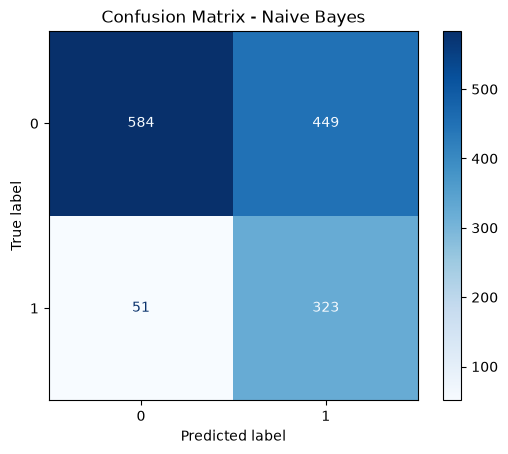

In [123]:
#ploting confusion matrix\
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)
plt.title("Confusion Matrix - Naive Bayes")
plt.show()

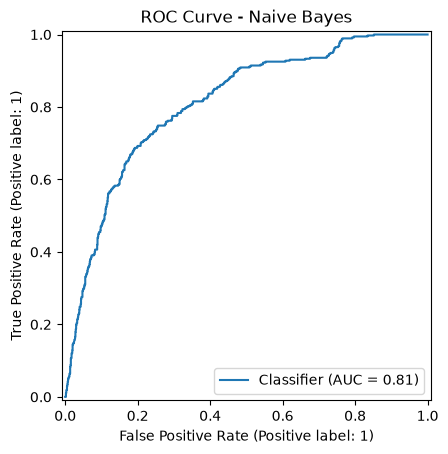

In [124]:
#ploting ROC Curve 
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("ROC Curve - Naive Bayes")
plt.show()

In [129]:
#AUC measures how well the model ranks positives above negatives across all possible thresholds, and 0.81 is well above the 0.5 "random guessing" baseline. Rule of thumb: 0.7-0.8 is "acceptable," 0.8-0.9 is "good"

# Naive Bayes Results & Observations

## Model Performance

| Metric | Score |
|--------|-------:|
| Accuracy | **64.46%** |
| Precision | **41.84%** |
| Recall | **86.36%** |
| F1 Score | **56.37%** |
| ROC-AUC | **81.02%** |

---

## Classification Report Summary

- Correctly identified **323 churn customers**.
- Correctly identified **584 non-churn customers**.
- Missed only **51 actual churn customers**.
- Incorrectly predicted **449 loyal customers as churn**.

---

## Confusion Matrix Interpretation

- **True Positives (323):** Customers who churned and were correctly predicted as churn.
- **True Negatives (584):** Customers who stayed and were correctly predicted as non-churn.
- **False Positives (449):** Customers predicted to churn but who actually stayed.
- **False Negatives (51):** Customers predicted to stay but who actually churned.

---

## Observations

- Naive Bayes achieved the **highest Recall (86.36%)** among all models tested.
- The model successfully captured most customers who were likely to churn.
- However, it produced a large number of **False Positives**, leading to low Precision (41.84%).
- The overall Accuracy (64.46%) was lower than other classification models.
- The ROC-AUC score (81.02%) indicates that the model still has good capability to distinguish between churn and non-churn customers.

---

## Business Interpretation

Naive Bayes is suitable when the business objective is to **identify as many potential churn customers as possible**, even if it results in more false alarms.

This model can be useful in customer retention campaigns where:
- Missing a churn customer is costly.
- Offering retention incentives to some loyal customers is acceptable.

However, if the business aims to minimize unnecessary retention costs and false alarms, models such as **Random Forest** or **Logistic Regression** provide a better balance between Precision, Accuracy, and Recall.

---

## Conclusion

Naive Bayes demonstrates excellent sensitivity toward churn detection but sacrifices overall Accuracy and Precision due to a high number of false positive predictions. It is best suited for scenarios where maximizing churn detection is more important than minimizing false alarms.

In [127]:
nb_result = {
    "Model": "Naive Bayes",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC-AUC": roc_auc
}

In [135]:
import pandas as pd

model_comparison = pd.DataFrame([
    log_result,
    knn_result,
    dt_result,
    rf_result,
    nb_result
])

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.786780,0.621711,0.505348,0.557522,0.814197
1,KNN,0.786780,0.621711,0.505348,0.557522,0.814197
2,Decision Tree,0.778252,0.580729,0.596257,0.588391,0.819709
3,Random Forest Tuned,0.794598,0.649123,0.494652,0.561457,0.835998
4,Naive Bayes,0.644634,0.418394,0.863636,0.563700,0.810182


# Support Vector Machine (SVM)

Support Vector Machine (SVM) is a supervised machine learning algorithm used for both classification and regression tasks.

The main objective of SVM is to find the optimal decision boundary (hyperplane) that maximizes the margin between different classes.

Unlike Decision Trees, SVM focuses only on the most important training samples called **Support Vectors**, making it effective for high-dimensional datasets.

In this project, a **Linear SVM** is used as the baseline model before exploring other kernel functions.

Since SVM is sensitive to the scale of features, the standardized dataset (`X_train_scaled`) is used for training.

In [130]:
#SVM(support vector machine)
from sklearn.svm import SVC

In [133]:
#creating Model
svm_model=SVC(
    kernel="linear",
    random_state=42,
    probability=True
)

In [134]:
#traning model
svm_model.fit(X_train_scaled, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [137]:
#predict Probability
y_pred = svm_model.predict(X_test_scaled) 
y_prob = svm_model.predict_proba(X_test_scaled)[:, 1] #predict_proba() returns probabilities for both classes
                                                     #[:, 1] selects the probability of the positive class (Churn = Yes)

In [138]:
print(y_pred[:10])
print(y_prob[:10])

[0 1 0 0 0 0 0 0 1 0]
[0.03112236 0.65679774 0.0507492  0.19578042 0.12749419 0.2841536
 0.07048296 0.17500585 0.73765849 0.0344884 ]


In [139]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", accuracy)
print("Precision :", precision)
print("Recall :", recall)
print("F1 Score :", f1)
print("ROC-AUC :", roc_auc)

print("\nClassification Report\n")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix\n")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.798862828713575
Precision : 0.6408668730650154
Recall : 0.553475935828877
F1 Score : 0.593974175035868
ROC-AUC : 0.82726573864607

Classification Report

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.64      0.55      0.59       374

    accuracy                           0.80      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407


Confusion Matrix

[[917 116]
 [167 207]]


# Support Vector Machine (SVM) Model Evaluation

The Support Vector Machine (SVM) model was trained and evaluated for customer churn prediction. SVM identifies an optimal decision boundary that separates churn and non-churn customers by maximizing the margin between different classes.

## Performance Metrics

| Metric | Score |
|--------|-------|
| Accuracy | **79.89%** |
| Precision | **64.09%** |
| Recall | **55.35%** |
| F1 Score | **59.40%** |
| ROC-AUC Score | **82.73%** |

---

## Confusion Matrix



### Interpretation

- **True Negative (917):**  
  The model correctly predicted customers who will not churn.

- **False Positive (116):**  
  Customers predicted as churn but actually remained with the service.

- **False Negative (167):**  
  Customers predicted as non-churn but actually left the service.

- **True Positive (207):**  
  The model correctly identified customers who churned.

---

## Classification Report Analysis

| Class | Precision | Recall | F1-score |
|------|-----------|--------|----------|
| Non-Churn (0) | 85% | 89% | 87% |
| Churn (1) | 64% | 55% | 59% |

### Class 0: Non-Churn Customers

- The model achieved:
  - **85% Precision**
  - **89% Recall**
  - **87% F1-score**

This indicates that SVM is highly effective at identifying customers who are likely to continue using the service.

### Class 1: Churn Customers

- The model achieved:
  - **64% Precision**
  - **55% Recall**
  - **59% F1-score**

The model successfully identified more than half of the actual churn customers. Compared with some other models, SVM provides a better balance between detecting churn customers and avoiding false churn predictions.

---

## Key Insights

- SVM achieved **79.89% accuracy**, showing strong overall classification performance.
- The **ROC-AUC score of 82.73%** indicates that the model has a good ability to distinguish between churn and non-churn customers.
- The recall score of **55.35%** shows that SVM can identify more potential churn customers compared to Random Forest Tuned.
- The model produced **207 True Positives**, meaning it successfully detected 207 customers who actually churned.

---

## Business Interpretation

For customer churn prediction, recall is an important metric because missing a potential churn customer can result in revenue loss.

SVM provides a good balance:

- Higher churn detection capability compared to models with lower recall.
- Good precision, reducing unnecessary retention efforts.
- Strong overall performance with balanced evaluation metrics.

---

## Conclusion

The SVM model provides a reliable solution for customer churn prediction with a strong balance between precision and recall.

With:
- **79.89% Accuracy**
- **55.35% Recall**
- **59.40% F1 Score**
- **82.73% ROC-AUC**

SVM can be considered a competitive model for identifying customers at risk of churn and will be compared with other algorithms for final model selection.

In [141]:
svm_model_result = {
    "Model": "SVM",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC-AUC": roc_auc
}

In [142]:
import pandas as pd

model_comparison = pd.DataFrame([
    log_result,
    knn_result,
    dt_result,
    rf_result,
    nb_result,
    svm_model_result
])

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.786780,0.621711,0.505348,0.557522,0.814197
1,KNN,0.786780,0.621711,0.505348,0.557522,0.814197
2,Decision Tree,0.778252,0.580729,0.596257,0.588391,0.819709
3,Random Forest Tuned,0.794598,0.649123,0.494652,0.561457,0.835998
4,Naive Bayes,0.644634,0.418394,0.863636,0.563700,0.810182
5,SVM,0.798863,0.640867,0.553476,0.593974,0.827266


In [143]:
from sklearn.ensemble import GradientBoostingClassifier

In [144]:
#creating and traning model(gb)
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [145]:
#class and probability prediction
y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:,1]

In [146]:
print(y_pred_gb[:10])
print(y_prob_gb[:10])

[0 1 0 0 0 0 0 0 1 0]
[0.02394121 0.5914853  0.0212927  0.14983496 0.08329697 0.44038329
 0.03377956 0.10330126 0.57539177 0.02489275]


In [147]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb)
recall_gb = recall_score(y_test, y_pred_gb)
f1_gb = f1_score(y_test, y_pred_gb)
roc_auc_gb = roc_auc_score(y_test, y_prob_gb)

print("Accuracy :", accuracy_gb)
print("Precision :", precision_gb)
print("Recall :", recall_gb)
print("F1 Score :", f1_gb)
print("ROC-AUC :", roc_auc_gb)

print("\nClassification Report\n")
print(classification_report(y_test,y_pred_gb))

print("\nConfusion Matrix\n")
print(confusion_matrix(y_test,y_pred_gb))

Accuracy : 0.7953091684434968
Precision : 0.6378205128205128
Recall : 0.5320855614973262
F1 Score : 0.5801749271137027
ROC-AUC : 0.8406619005958451

Classification Report

              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407


Confusion Matrix

[[920 113]
 [175 199]]


# Gradient Boosting Model Evaluation

The Gradient Boosting Classifier was trained and evaluated for customer churn prediction. Gradient Boosting builds multiple weak learners sequentially, where each new model focuses on correcting the errors made by previous models. This helps improve prediction accuracy and generalization.

## Performance Metrics

| Metric | Score |
|--------|-------|
| Accuracy | **79.53%** |
| Precision | **63.78%** |
| Recall | **53.21%** |
| F1 Score | **58.02%** |
| ROC-AUC Score | **84.07%** |

---

## Confusion Matrix



### Interpretation

- **True Negative (920):**  
  The model correctly predicted customers who will not churn.

- **False Positive (113):**  
  Customers predicted as churn but actually remained with the company.

- **False Negative (175):**  
  Customers predicted as non-churn but actually churned.

- **True Positive (199):**  
  The model correctly identified customers who churned.

---

## Classification Report Analysis

| Class | Precision | Recall | F1-score |
|------|-----------|--------|----------|
| Non-Churn (0) | 84% | 89% | 86% |
| Churn (1) | 64% | 53% | 58% |

### Non-Churn Customers (Class 0)

The model performs strongly in identifying customers who are likely to stay:

- Precision: **84%**
- Recall: **89%**
- F1-score: **86%**

This indicates that Gradient Boosting can accurately classify loyal customers.

### Churn Customers (Class 1)

For churn detection:

- Precision: **64%**
- Recall: **53%**
- F1-score: **58%**

The model identifies more than half of the actual churn customers while maintaining reasonable precision.

---

## Key Insights

- Gradient Boosting achieved **79.53% accuracy**, showing strong overall predictive performance.
- The model achieved the highest **ROC-AUC score (84.07%)** among the evaluated models, indicating excellent ability to distinguish between churn and non-churn customers.
- The model correctly identified **199 churn customers**, while reducing false predictions.
- Compared with simpler models, Gradient Boosting captures more complex patterns in customer behavior.

---

## Business Interpretation

Gradient Boosting provides a strong balance between identifying churn customers and avoiding unnecessary retention efforts.

- Higher ROC-AUC helps prioritize customers based on churn probability.
- Good precision reduces unnecessary marketing or retention campaigns.
- Improved detection of churn customers helps businesses take proactive actions.

---

## Conclusion

The Gradient Boosting model provides strong performance for customer churn prediction with:

- **79.53% Accuracy**
- **53.21% Recall**
- **58.02% F1 Score**
- **84.07% ROC-AUC**

With the highest ROC-AUC score among the tested models, Gradient Boosting is a strong candidate for the final churn prediction model and will be considered during final model selection.

In [148]:
gb_result = evaluate_model(
    "Gradient Boosting",
    y_test,
    y_pred_gb,
    y_prob_gb
)

In [149]:
model_comparison = pd.DataFrame([
    log_result,
    knn_result,
    dt_result,
    rf_result,
    nb_result,
    gb_result
])

model_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
5,Gradient Boosting,0.795309,0.637821,0.532086,0.580175,0.840662
3,Random Forest Tuned,0.794598,0.649123,0.494652,0.561457,0.835998
2,Decision Tree,0.778252,0.580729,0.596257,0.588391,0.819709
0,Logistic Regression,0.786780,0.621711,0.505348,0.557522,0.814197
1,KNN,0.786780,0.621711,0.505348,0.557522,0.814197
4,Naive Bayes,0.644634,0.418394,0.863636,0.563700,0.810182


In [150]:
#adaboost
from sklearn.ensemble import AdaBoostClassifier

In [151]:
#create model
ada_model = AdaBoostClassifier(random_state=42)
#train model
ada_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](50,)","[0.27,0.35,0.34,...,0.5 ,0.5 ,0.5 ]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[1.02,0.6 ,0.65,...,0.01,0.01,0.01]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](30,)","[0. ,0.02,0. ,...,0. ,0.07,0. ]"


## Tree-based ensemble models like:

1) AdaBoost
2) Random Forest
3) Gradient Boosting
4) Decision Tree
5) XGBoost

Do not need feature scaling thats why i didint use (X_train_scaled)

In [152]:
y_pred_ada = ada_model.predict(X_test)
y_prob_ada = ada_model.predict_proba(X_test)[:,1]

In [153]:
print(y_pred_ada[:10])
print(y_prob_ada[:10])

[0 1 0 0 0 0 0 0 1 0]
[0.28548207 0.50714695 0.24075831 0.39561289 0.33934593 0.48158102
 0.29701308 0.37079632 0.55553267 0.2508412 ]


In [154]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

accuracy_ada = accuracy_score(y_test, y_pred_ada)
precision_ada = precision_score(y_test, y_pred_ada)
recall_ada = recall_score(y_test, y_pred_ada)
f1_ada = f1_score(y_test, y_pred_ada)
roc_auc_ada = roc_auc_score(y_test, y_prob_ada)

print("Accuracy :", accuracy_ada)
print("Precision :", precision_ada)
print("Recall :", recall_ada)
print("F1 Score :", f1_ada)
print("ROC-AUC :", roc_auc_ada)

print("\nClassification Report\n")
print(classification_report(y_test, y_pred_ada))

print("\nConfusion Matrix\n")
print(confusion_matrix(y_test, y_pred_ada))

Accuracy : 0.7953091684434968
Precision : 0.6482758620689655
Recall : 0.5026737967914439
F1 Score : 0.5662650602409639
ROC-AUC : 0.8408301453116669

Classification Report

              precision    recall  f1-score   support

           0       0.83      0.90      0.87      1033
           1       0.65      0.50      0.57       374

    accuracy                           0.80      1407
   macro avg       0.74      0.70      0.72      1407
weighted avg       0.78      0.80      0.79      1407


Confusion Matrix

[[931 102]
 [186 188]]


# AdaBoost Model Evaluation

The AdaBoost (Adaptive Boosting) classifier was trained and evaluated for customer churn prediction. AdaBoost combines multiple weak learners sequentially and gives more importance to previously misclassified samples, improving the overall classification performance.

## Performance Metrics

| Metric | Score |
|--------|-------|
| Accuracy | **79.53%** |
| Precision | **64.83%** |
| Recall | **50.27%** |
| F1 Score | **56.63%** |
| ROC-AUC Score | **84.08%** |

---

## Confusion Matrix



### Interpretation

- **True Negative (931):**  
  The model correctly predicted customers who will not churn.

- **False Positive (102):**  
  Customers predicted as churn but actually remained with the company.

- **False Negative (186):**  
  Customers predicted as non-churn but actually churned.

- **True Positive (188):**  
  The model correctly identified customers who churned.

---

## Classification Report Analysis

| Class | Precision | Recall | F1-score |
|------|-----------|--------|----------|
| Non-Churn (0) | 83% | 90% | 87% |
| Churn (1) | 65% | 50% | 57% |

### Non-Churn Customers (Class 0)

The model performs well in identifying customers who are likely to stay:

- Precision: **83%**
- Recall: **90%**
- F1-score: **87%**

This indicates that AdaBoost effectively classifies loyal customers.

### Churn Customers (Class 1)

For churn prediction:

- Precision: **65%**
- Recall: **50%**
- F1-score: **57%**

The model provides good precision when predicting churn but misses some customers who actually leave.

---

## Key Insights

- AdaBoost achieved **79.53% accuracy**, showing strong overall predictive capability.
- The model achieved the highest **ROC-AUC score (84.08%)** among the evaluated models.
- The high ROC-AUC score indicates that AdaBoost has strong ability to differentiate between churn and non-churn customers.
- The model produced **188 True Positives**, successfully identifying customers who are likely to leave.
- Compared with simpler models, AdaBoost captures more complex patterns by combining multiple weak learners.

---

## Business Interpretation

AdaBoost provides a balanced approach for churn prediction:

- Higher precision helps reduce unnecessary retention campaigns.
- Strong ROC-AUC helps rank customers according to churn probability.
- Identified churn-risk customers can be targeted with personalized retention strategies.

---

## Conclusion

The AdaBoost model achieved strong performance with:

- **79.53% Accuracy**
- **50.27% Recall**
- **56.63% F1 Score**
- **84.08% ROC-AUC**

With the highest ROC-AUC score among the tested models, AdaBoost becomes a strong candidate for the final churn prediction model. However, final selection should consider business objectives such as maximizing churn detection (recall) or achieving overall prediction reliability.

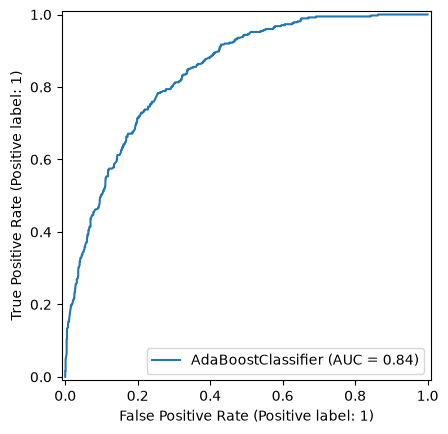

In [172]:
#ROC Curve
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    ada_model,
    X_test,
    y_test
)

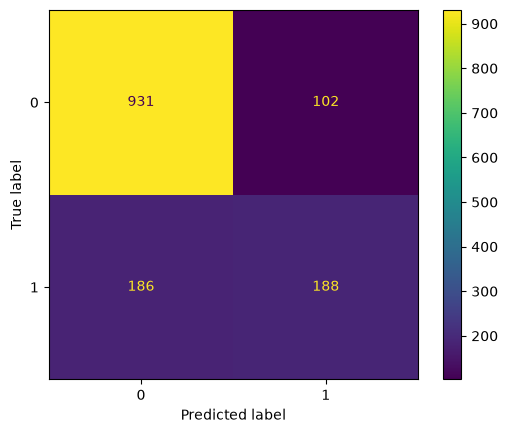

In [173]:
#Confusion Matrix
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_ada
)

In [174]:
#Feature Importance
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": ada_model.feature_importances_
})


importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(10)

,Feature,Importance
4,tenure,0.428969
26,Contract_Two year,0.087644
11,InternetService_Fiber optic,0.083551
7,MonthlyCharges,0.081486
28,PaymentMethod_Electronic check,0.074942
19,TechSupport_No internet service,0.041704
25,Contract_One year,0.035692
15,OnlineBackup_No internet service,0.025060
24,StreamingMovies_Yes,0.022055
5,PhoneService,0.019968


In [155]:
ada_result = evaluate_model(
    "AdaBoost",
    y_test,
    y_pred_ada,
    y_prob_ada
)

In [156]:
model_comparison = pd.DataFrame([
    log_result,
    knn_result,
    dt_result,
    rf_result,
    nb_result,
    gb_result,
    ada_result
])

model_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
6,AdaBoost,0.795309,0.648276,0.502674,0.566265,0.840830
5,Gradient Boosting,0.795309,0.637821,0.532086,0.580175,0.840662
3,Random Forest Tuned,0.794598,0.649123,0.494652,0.561457,0.835998
2,Decision Tree,0.778252,0.580729,0.596257,0.588391,0.819709
0,Logistic Regression,0.786780,0.621711,0.505348,0.557522,0.814197
1,KNN,0.786780,0.621711,0.505348,0.557522,0.814197
4,Naive Bayes,0.644634,0.418394,0.863636,0.563700,0.810182


In [158]:
#XGBoost (Extreme Gradient Boosting)
from xgboost import XGBClassifier

In [159]:
xgb_model = XGBClassifier(
    random_state=42,  #random_state=42 → makes sure reproducible results
    eval_metric='logloss' #eval_metric='logloss' → evaluates classification performance during training
)

xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [160]:
#class and probability prediction
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:,1]

In [161]:
print(y_pred_xgb[:10])
print(y_prob_xgb[:10])

[0 1 0 0 0 0 0 0 1 0]
[6.7509996e-04 7.6841182e-01 1.4323405e-02 3.7769973e-02 1.1782772e-01
 4.2757973e-01 2.6492190e-02 3.7036888e-02 7.6849699e-01 9.6847001e-04]


In [162]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("Accuracy :", accuracy_xgb)
print("Precision :", precision_xgb)
print("Recall :", recall_xgb)
print("F1 Score :", f1_xgb)
print("ROC-AUC :", roc_auc_xgb)

print("\nClassification Report\n")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix\n")
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy : 0.7711442786069652
Precision : 0.5760233918128655
Recall : 0.5267379679144385
F1 Score : 0.5502793296089385
ROC-AUC : 0.8113899084231069

Classification Report

              precision    recall  f1-score   support

           0       0.83      0.86      0.85      1033
           1       0.58      0.53      0.55       374

    accuracy                           0.77      1407
   macro avg       0.70      0.69      0.70      1407
weighted avg       0.77      0.77      0.77      1407


Confusion Matrix

[[888 145]
 [177 197]]


# XGBoost Model Evaluation

The XGBoost (Extreme Gradient Boosting) classifier was trained and evaluated for customer churn prediction. XGBoost is an advanced ensemble learning algorithm that builds multiple decision trees sequentially, where each new tree focuses on correcting the errors made by previous trees.

## Performance Metrics

| Metric | Score |
|--------|-------|
| Accuracy | **77.11%** |
| Precision | **57.60%** |
| Recall | **52.67%** |
| F1 Score | **55.03%** |
| ROC-AUC Score | **81.14%** |

---

## Confusion Matrix



### Interpretation

- **True Negative (888):**  
  The model correctly predicted customers who will not churn.

- **False Positive (145):**  
  Customers predicted as churn but actually stayed.

- **False Negative (177):**  
  Customers predicted as non-churn but actually left.

- **True Positive (197):**  
  The model correctly identified customers who churned.

---

## Classification Report Analysis

| Class | Precision | Recall | F1-score |
|------|-----------|--------|----------|
| Non-Churn (0) | 83% | 86% | 85% |
| Churn (1) | 58% | 53% | 55% |

### Non-Churn Customers (Class 0)

The model performs reasonably well in identifying customers who are likely to stay:

- Precision: **83%**
- Recall: **86%**
- F1-score: **85%**

This indicates that XGBoost can classify non-churning customers effectively.

### Churn Customers (Class 1)

For churn prediction:

- Precision: **58%**
- Recall: **53%**
- F1-score: **55%**

The model identifies more than half of actual churn customers but has lower precision compared to other ensemble models.

---

## Key Insights

- XGBoost achieved **77.11% accuracy**, showing moderate predictive performance.
- The **ROC-AUC score of 81.14%** indicates that the model has a reasonable ability to distinguish between churn and non-churn customers.
- The model correctly identified **197 churn customers**, but it also generated a higher number of false positives (**145 customers**).
- Compared with AdaBoost, Gradient Boosting, and Random Forest, XGBoost showed lower performance on this dataset.

---

## Business Interpretation

XGBoost can still be useful for churn prediction because:

- It captures complex relationships between customer features.
- It provides probability-based churn predictions.
- It can be improved further through hyperparameter tuning.

Possible improvements:
- Optimize parameters using GridSearchCV or RandomizedSearchCV.
- Apply class balancing techniques such as SMOTE.
- Adjust classification threshold to improve churn recall.

---

## Conclusion

The XGBoost model achieved:

- **77.11% Accuracy**
- **52.67% Recall**
- **55.03% F1 Score**
- **81.14% ROC-AUC**

Although XGBoost is a powerful boosting algorithm, its default configuration did not outperform other models in this churn prediction task. Further tuning and optimization may improve its performance.

In [163]:
xgb_result = evaluate_model(
    "XGBoost",
    y_test,
    y_pred_xgb,
    y_prob_xgb
)

In [164]:
model_comparison = pd.DataFrame([
    log_result,
    knn_result,
    dt_result,
    rf_result,
    nb_result,
    gb_result,
    ada_result,
    xgb_result
])

model_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
6,AdaBoost,0.795309,0.648276,0.502674,0.566265,0.840830
5,Gradient Boosting,0.795309,0.637821,0.532086,0.580175,0.840662
3,Random Forest Tuned,0.794598,0.649123,0.494652,0.561457,0.835998
2,Decision Tree,0.778252,0.580729,0.596257,0.588391,0.819709
0,Logistic Regression,0.786780,0.621711,0.505348,0.557522,0.814197
1,KNN,0.786780,0.621711,0.505348,0.557522,0.814197
7,XGBoost,0.771144,0.576023,0.526738,0.550279,0.811390
4,Naive Bayes,0.644634,0.418394,0.863636,0.563700,0.810182


# Final Model Comparison and Analysis

After training and evaluating multiple machine learning classification algorithms, the models were compared using key evaluation metrics such as Accuracy, Precision, Recall, F1 Score, and ROC-AUC Score.

## Model Performance Comparison

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|-------|----------|-----------|--------|----------|---------|
| AdaBoost | **79.53%** | 64.83% | 50.27% | 56.63% | **84.08%** |
| Gradient Boosting | **79.53%** | 63.78% | 53.21% | **58.02%** | 84.07% |
| Random Forest Tuned | 79.46% | **64.91%** | 49.47% | 56.15% | 83.60% |
| Decision Tree | 77.83% | 58.07% | **59.63%** | **58.84%** | 81.97% |
| Logistic Regression | 78.68% | 62.17% | 50.53% | 55.75% | 81.42% |
| KNN | 78.68% | 62.17% | 50.53% | 55.75% | 81.42% |
| XGBoost | 77.11% | 57.60% | 52.67% | 55.03% | 81.14% |
| Naive Bayes | 64.46% | 41.84% | **86.36%** | 56.37% | 81.02% |

---

# Model Performance Interpretation

## AdaBoost

- Achieved the highest **ROC-AUC score (84.08%)**, showing excellent ability to separate churn and non-churn customers.
- Achieved strong precision (**64.83%**), reducing unnecessary retention efforts.
- Provides a good balance between prediction accuracy and churn identification.

## Gradient Boosting

- Achieved the highest **F1 Score among boosting models (58.02%)**.
- Provides a balanced trade-off between precision and recall.
- Performs well in identifying complex patterns in customer behavior.

## Random Forest Tuned

- Achieved the highest **Precision (64.91%)** among all models.
- Hyperparameter tuning improved its performance compared to the baseline Random Forest.
- Provides reliable predictions with fewer false churn classifications.

## Decision Tree

- Achieved the highest **Recall (59.63%)** among traditional models.
- Better at identifying customers who are likely to churn.
- However, it has lower precision compared to ensemble models.

## Logistic Regression and KNN

- Both models achieved similar performance.
- They provide a good baseline but are less effective at capturing complex customer behavior patterns compared to ensemble methods.

## XGBoost

- XGBoost provided reasonable performance but achieved lower scores compared to other boosting algorithms.
- Further hyperparameter tuning may improve its performance.

## Naive Bayes

- Achieved the highest recall (**86.36%**), meaning it identifies most churn customers.
- However, it produced many false positives due to lower precision (**41.84%**).
- Suitable when the business priority is only detecting maximum possible churn cases.

---

# Business Objective Achievement

## Objective

The primary objective of this project was:

> To develop a machine learning model capable of predicting customer churn and identifying customers who are likely to leave the service, enabling businesses to take proactive retention actions.

## Objective Achievement

The objective was successfully achieved by:

- Building multiple classification models for churn prediction.
- Comparing models using multiple evaluation metrics.
- Identifying important trade-offs between precision and recall.
- Selecting the most suitable model based on business requirements.

The final models provide valuable insights into customer churn behavior and can support data-driven retention strategies.

---

# Final Model Selection Insights

The best model depends on the business goal:

### 1. For Overall Reliable Churn Prediction

**Recommended Model: AdaBoost**

Reasons:
- Highest ROC-AUC score (**84.08%**)
- Strong precision (**64.83%**)
- Good overall classification performance

AdaBoost provides better ranking capability to identify customers with higher churn probability.

---

### 2. For Detecting Maximum Number of Churn Customers

**Recommended Model: Naive Bayes / Decision Tree**

Reasons:
- Naive Bayes achieved the highest recall (**86.36%**)
- Decision Tree achieved strong recall (**59.63%**)

These models are useful when missing a potential churn customer is more costly than contacting some customers unnecessarily.

---

### 3. For Balanced Performance

**Recommended Model: Gradient Boosting**

Reasons:
- Strong ROC-AUC (**84.07%**)
- Highest F1 Score among boosting models (**58.02%**)
- Good balance between precision and recall

---

# Final Conclusion

The machine learning models successfully predicted customer churn with good performance.

Among all evaluated models:

- **AdaBoost achieved the highest ROC-AUC score (84.08%)**, making it the best overall model for ranking churn probabilities.
- **Gradient Boosting provided the best balance between precision and recall.**
- **Decision Tree and Naive Bayes achieved higher recall**, making them useful for aggressive churn detection strategies.

For this customer churn prediction project, **AdaBoost is selected as the final model** because it provides the best overall predictive capability and helps businesses identify high-risk customers for targeted retention strategies.

In [165]:
#AdaBoost (Best ROC-AUC: 84.08%)
final_model = ada_model

In [166]:
import joblib
joblib.dump(final_model, "customer_churn_model.pk1")

['customer_churn_model.pk1']

In [167]:
#saving binary encoding
joblib.dump(
    binary_mapping,
    "binary_mapping.pkl"
)

['binary_mapping.pkl']

In [168]:
#one hot encoding
feature_columns = X_train.columns

joblib.dump(
    feature_columns,
    "feature_columns.pkl"
)

['feature_columns.pkl']

In [169]:
#saving model comparison
model_comparison.to_csv(
    "model_comparison.csv",
    index=False
)

In [175]:
import joblib

# Save AdaBoost model
joblib.dump(
    ada_model,
    "ada_churn_model.pkl"
)

# Save binary encoding mapping
joblib.dump(
    binary_mapping,
    "binary_mapping.pkl"
)

# Save feature columns
feature_columns = X_train.columns

joblib.dump(
    feature_columns,
    "feature_columns.pkl"
)

print("Files saved successfully!")

Files saved successfully!


In [176]:
import os

os.listdir()

['-1.14-windows.xml',
 '.bash_history',
 '.copilot',
 '.gitconfig',
 '.ipynb_checkpoints',
 '.ipython',
 '.jupyter',
 '.lesshst',
 '.MCTranscodingSDK',
 '.ms-ad',
 '.openshot_qt',
 '.python_history',
 '.thumbnails',
 '.viminfo',
 '.viminfo.tmp',
 '.vscode',
 '.vscode-shared',
 '3D Objects',
 'ada_churn_model.pkl',
 'all about logistic regression2.ipynb',
 'ansel',
 'AppData',
 'Application Data',
 'bankcustomerchurn.ipynb',
 'binary_mapping.pkl',
 'blenderkit_data',
 'churn',
 'Contacts',
 'Cookies',
 'CrossDevice',
 'customer_churn_model.pk1',
 'Customer_Segmentation_DBSCAN.ipynb',
 'Customer_Segmentation_Hierarchical.ipynb',
 'DBSCANCustomersegmentation.ipynb',
 'decision tree.ipynb',
 'Desktop',
 'Documents',
 'Downloads',
 'Favorites',
 'feature_columns.pkl',
 'fullworkflow.ipynb',
 'Lightworks',
 'linear_regression.ipynb',
 'Links',
 'Local Settings',
 'mallcustomers.ipynb',
 'model_comparison.csv',
 'Music',
 'My Documents',
 'naive_bayes.ipynb',
 'NetHood',
 'Notepad++',
 'NTUSE